AI Lab - initial guidelines to generate your reports
This is a small sample notebook for you with some information that you might use to generate you reports. It has some guidelines, some initial ideas, and some questions for you to think about and discuss. This is only an initial notebook, please organize as you like.

I expect you to grow your notebooks into full project reports, with your work and results, the description of your steps, justification for your choices, and your ideas and considerations. Please use both text and visualisations to clarify results and concepts. Please try also to capture the discussion we had in class, and the discussion you had afterwards. The final reports should reflect the work of your group and your very own results, ideas and discussion.

If you need domain specific knowlegde you can check again some of the handouts, and you can also explore further some of the links in the handouts, or you can ask. However, please try not to be too domain specific in your thinking and in your reports, try to to apply the theory you have learnt and use your observations and results to extract general underlying concepts.

For the first AI Lab day we progress all together, and below I give you some more pointers for the first analysis steps. This is so you can familizarize with the data. After this, from day 2, you will progress more independently, and for days 3 and 4 you will divide into groups for the data challenge.

Introduction
Please include a short introduction based on what we discussed in class:

Background
Overall Aim
Specific Objectives
[...]

This should be based on what we discussed in class. Please ask any questions you have or clarifications, you can also consult the handouts. I would probably aim for no more than 200 words for this section.

Materials and Methods

Please include:

A short description of the data and how they were obtained.
A short description of the methods you will use and why.
[...]

I would aim for no longer than 300 words, but you could also provide more details and justification of data and methods when you load them/use them in the following sections.

one dataset in detail and the other just the main pointe -> just put the results

In [573]:
#Remember you can use command line mode if installations are needed
#!pip install numpy
#!pip install matplotlib
#!pip install seaborn
#!pip install pandas
#!pip install scikit-learn
#!pip uninstall umap
#!pip install umap-learn
#!pip install statsmodels

import sys
import sklearn

# import umap
import matplotlib as mp
import matplotlib.pyplot
from sklearn.decomposition import PCA
from statsmodels.stats.multitest import multipletests
from scipy.stats import ttest_ind
#from umap.umap_ import UMAP
import seaborn as sns
# import plotly as py
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt             #visualisation
import seaborn as sns   #visualisation
from scipy.sparse import csr_matrix
%matplotlib inline     
sns.set(color_codes=True)
#[....] for you to add


Exploratory data analysis
First we load the data. There are four datasets. They correspond to four different experiments in two different cell lines, and using two different single cell RNA sequencing techniques. You might proceed one experiment at a time, or download the metadata for all experiments and discuss them together. Here I show the example for one of the datasets.

MCF7 SmartSeq experiment
First we read in the metadata. There are 4 metadata files. One for each experiment. They are tab delimited file TSV.

# Meta Data Set

In [574]:
df_meta = pd.read_csv("MCF7_SmartS_MetaData.tsv",delimiter="\t",engine='python',index_col=0)
print("Dataframe dimensions:", np.shape(df_meta))
print("First column: ", df_meta.iloc[ : , 0])

Dataframe dimensions: (383, 8)
First column:  Filename
output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam      MCF7
output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam      MCF7
                                                            ... 
output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam    MCF7
output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam    MCF7
Name: Cell Line, Length: 383, dtype: object


In [575]:
df_meta.head(5)   

,Cell Line,Lane,Pos,Condition,Hours,Cell name,PreprocessingTag,ProcessingComments
Filename,,,,,,,,
output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam,MCF7,output.STAR.1,A10,Hypo,72,S28,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam,MCF7,output.STAR.1,A11,Hypo,72,S29,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam,MCF7,output.STAR.1,A12,Hypo,72,S30,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam,MCF7,output.STAR.1,A1,Norm,72,S1,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"
output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam,MCF7,output.STAR.1,A2,Norm,72,S2,Aligned.sortedByCoord.out.bam,"STAR,FeatureCounts"


Each row represents a single data entry, while columns represent different attributes: \
Column 1: File names of aligned BAM files. \
Column 2: Cell line information; in this case, MCF7 (derived from breast cancer cells). A cell line is a population of cells that are derived from a single cell or a small number of cells and have been cultured and propagated in vitro (in a laboratory setting) for experimental or research purposes \
Column 3: Information related to the STAR and FeatureCounts tools used for data analysis ***(?)***. 
Column 4: Sample names or identifiers. \
Column 5: Treatment condition information. \
Column 6: Could represent the amount of time that the samples were exposed to a particular experimental condition, treatment, or manipulation (72 hours, in this case). \
Column 7: Cell name. \
Column 8: "Aligned.sortedByCoord.out.bam" represents a file generated from an alignment step in a bioinformatics analysis pipeline. \
Column 9: "STAR,FeatureCounts" indicates that both STAR and FeatureCounts software tools were used in the data analysis pipeline for processing the given dataset. 

# Unfiltered Data

## Exploratory Data Analysis (EDA)

In [576]:
df = pd.read_csv("MCF7_SmartS_Unfiltered_Data.txt",delimiter="\ ",engine='python',index_col=0)
print("Dataframe dimensions:", np.shape(df))
print("First column: ", df.iloc[ : , 0])

Dataframe dimensions: (22934, 383)
First column:  "WASH7P"         0
"MIR6859-1"      0
"WASH9P"         1
"OR4F29"         0
"MTND1P23"       0
              ... 
"MT-TE"          4
"MT-CYB"       270
"MT-TT"          0
"MT-TP"          5
"MAFIP"          8
Name: "output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam", Length: 22934, dtype: int64


For each data file, describe its structure and content. \

File dimensions \
Rows represent different types of genes \
Columns are different cells \
Numbers represent how many times a gene is expressed in a cell\
This dataframe uses Symbols to identify genes (e.g. You can add the discussion we had in class on identifiers) [...]


In [577]:
print(df.shape) # How large the file is
print('Number of Samples:', df.shape[0])
print('Number of Features:', df.shape[1])

(22934, 383)
Number of Samples: 22934
Number of Features: 383


In [578]:
df.head(5)  

,"""output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A7_Hypo_S25_Aligned.sortedByCoord.out.bam""",...,"""output.STAR.4_H14_Hypo_S383_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H1_Norm_S355_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H2_Norm_S356_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"""
"""WASH7P""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,1,0,0,0,1,0,1
"""MIR6859-1""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""WASH9P""",1,0,0,0,0,1,10,1,0,0,...,1,1,0,0,0,0,1,1,4,5
"""OR4F29""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
"""MTND1P23""",0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [579]:
list(df.columns)[0:10] # Names of the cells (only first 10)

['"output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam"',
 '"output.STAR.1_A7_Hypo_S25_Aligned.sortedByCoord.out.bam"']

In [580]:
df.index # Names of genes

Index(['"WASH7P"', '"MIR6859-1"', '"WASH9P"', '"OR4F29"', '"MTND1P23"',
       '"MTND2P28"', '"MTCO1P12"', '"MTCO2P12"', '"MTATP8P1"', '"MTATP6P1"',
       ...
       '"MT-TH"', '"MT-TS2"', '"MT-TL2"', '"MT-ND5"', '"MT-ND6"', '"MT-TE"',
       '"MT-CYB"', '"MT-TT"', '"MT-TP"', '"MAFIP"'],
      dtype='object', length=22934)

Exploratory data analysis include a broad range of possible tasks: \\

what can you observe by looking at the data (maybe use some plots to explain) \\

In [581]:
df.dtypes

"output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam"      int64
"output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam"      int64
                                                              ...  
"output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam"    int64
"output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"    int64
Length: 383, dtype: object

In [582]:
# Check if all data types are numerical
is_numerical = all(df[col].dtype.kind in 'fi' for col in df.columns)

if is_numerical:
    print("All data types are numerical.")
else:
    print("Not all data types are numerical.")

All data types are numerical.


The aim is to understand the data by summarizing their main characteristics (e.g. tables with statistics or visually). This step is the very first one when we analyse the data. It can be time consuming but it is very useful to understand the data, perform some quality control, and define the downstream analysis. \\

Of note, there are ways of carrying out EDA and some steps that are domain specific, and even in the same domain sometimes there are different ways of carrying out EDA. It might depends on the specific technology or the specific question. However, most of the concepts are general and applicable to many contexts. The focus should be on the general context. \\

You have an "unfiltered" data file. These are data are matrixes of counts, no filter was applied and no normalization was applied. It is a good idea to start to explore this first to understand the issues with the dataset and discuss them, and what are the general implications of the issues you encounter. \\

You have also "filtered" data and "normalized" data. These have been pre-processed for you so eliminate some of the issues. You can use these to train your classifiers.

### Missing Values

In [583]:
print(df.isnull().sum())

"output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam"      0
"output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam"      0
                                                             ..
"output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"    0
Length: 383, dtype: int64


In [584]:
def null_percentage(col):
    possible_nulls = [None, np.nan, 'None', '?']
    null_count = col.isin(possible_nulls).sum()
    total_count = len(col)
    return round(null_count / total_count * 100)

# Calculate the percentage of null values in each column
df.apply(null_percentage)

"output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam"    0
"output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam"      0
"output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam"      0
                                                             ..
"output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam"    0
"output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"    0
Length: 383, dtype: int64

In [585]:
df.isnull().sum().sum()

0

Since the sum of missing values of every cell is 0, we can state that there are no missing values.

### Duplicates

Finding duplicate rows is useful because it can help identify and remove redundant or unnecessary data from the dataset. They can arise due to data entry errors, measurement errors, or other factors, and can lead to biased or misleading results if not handled properly. By removing duplicate rows, we can ensure that the dataset is clean, accurate, and representative of the underlying population. <br>
We start by checking if we have any duplicate genes (rows).

In [586]:
duplicate_rows_tot = df.duplicated(keep=False).sum()
print(f"There are {duplicate_rows_tot} duplicate rows.")

There are 56 duplicate rows.


Now we want to understand which rows are the duplicates. We print them all.

In [587]:
# Identify duplicate rows
duplicate_rows = df.duplicated(keep=False)

# Print the duplicate rows
print(df[duplicate_rows])

                   "output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"  \
"SHISAL2A"                                                         0            
"IL12RB2"                                                          0            
"S1PR1"                                                            0            
"CD84"                                                             0            
"GNLY"                                                             0            
"FAR2P3"                                                           0            
"KLF2P3"                                                           0            
"PABPC1P2"                                                         0            
"UGT1A8"                                                           0            
"UGT1A9"                                                           0            
"SLC22A14"                                                         0            
"COQ10BP2"                  

We have to note that when we remove one of the duplicate genes, we may lose important biological information. For example, the gene that has been removed could be the one that has been previously annotated or studied extensively in other studies. If we remove this gene without recording it in a log file, we could miss an important biological link between the current study and historical studies. We procede by creating a new dataframe where we store all the above found duplicates.

In [588]:
# new dataframe containing all duplicate rows
duplicate_rows_df = df[df.duplicated(keep=False)]

Next step is understanding where exactly the duplicates are, meaning which genes are the duplicates of others. We calculate the correlation matrix which measures the linear relationship between pairs of genes across the duplicated rows. Each element of the correlation matrix represents the correlation coefficient between the expression values of two genes in the duplicated rows. The genes with correlation coefficient 1 are the duplicates.

In [589]:
duplicate_rows_df_t = duplicate_rows_df.T
c_dupl = duplicate_rows_df_t.corr()

# Find the genes that have a correlation coefficient of 1
duplicate_genes = []
for gene_1 in c_dupl.index:
    for gene_2 in c_dupl.columns:
        if gene_1 != gene_2 and c_dupl.loc[gene_1, gene_2] == 1 and gene_1 not in duplicate_genes and gene_2 not in duplicate_genes:
            duplicate_genes.append(gene_1)
            print(f"{gene_1} and {gene_2} are duplicates")

"SHISAL2A" and "COQ10BP2" are duplicates
"IL12RB2" and "GALNT17" are duplicates
"S1PR1" and "MUC6" are duplicates
"CD84" and "WDR95P" are duplicates
"GNLY" and "KCNS2" are duplicates
"FAR2P3" and "KLF2P3" are duplicates
"PABPC1P2" and "SLC22A14" are duplicates
"UGT1A8" and "UGT1A9" are duplicates
"PANDAR" and "LAP3P2" are duplicates
"RPL22P16" and "RNA5SP450" are duplicates
"GALNT17" and "PON1" are duplicates
"HTR5A" and "RNU6-539P" are duplicates
"SNORA36A" and "MIR664B" are duplicates
"CSMD1" and "SEZ6L" are duplicates
"KCNS2" and "BCL6B" are duplicates
"MIR548AA1" and "MIR548D1" are duplicates
"MTCO2P11" and "CACYBPP1" are duplicates
"CLCN3P1" and "OTOP3" are duplicates
"SUGT1P4-STRA6LP" and "STRA6LP" are duplicates
"VSTM4" and "PSG1" are duplicates
"LINC00856" and "LINC00595" are duplicates
"LINC00477" and "KNOP1P1" are duplicates
"MIR20A" and "MIR19B1" are duplicates
"RPL21P5" and "RBFOX1" are duplicates
"SNRPN" and "SNURF" are duplicates
"LINC02183" and "ADAMTS5" are duplicates
"

Finally, we drop the duplicated genes keeping the first one of the duplicates that appears. Furthermore, we also create a list containing all the genes that are removed so that we have that information stored as well.

In [590]:
# Create a list of gene names before dropping duplicates
genes_before_drop = list(df.index)

# Drop duplicates and keep track of removed genes
removed_genes = set()
df.drop_duplicates(keep='first', inplace=True)
for gene_1 in genes_before_drop:
    if gene_1 not in df.index:
        removed_genes.add(gene_1)

# Print the list of removed genes
print("Removed genes:", removed_genes)
# check the new size of dataframe to see if everything was done correctly
print(df.shape) 

Removed genes: {'"GALNT17"', '"PON1"', '"PSG1"', '"UGT1A9"', '"LINC00595"', '"MUC6"', '"CCL3L1"', '"KNOP1P1"', '"BCL6B"', '"SLC22A14"', '"CACYBPP1"', '"ADAMTS5"', '"RNU6-539P"', '"KLF2P3"', '"RNA5SP450"', '"LAP3P2"', '"WDR95P"', '"MIR548D1"', '"KCNS2"', '"STRA6LP"', '"MIR3191"', '"SEZ6L"', '"OTOP3"', '"MIR664B"', '"MIR19B1"', '"COQ10BP2"', '"SNURF"', '"ASPA"', '"RBFOX1"'}
(22905, 383)


In some cases, as a result of errors in data collection or processing, duplicated columns can appear as well. Having duplicated columns can cause problems in data analysis and modeling since they can introduce redundancy and skew the results. We proceed by checking if there are any.

In [591]:
duplicate_cols = df.columns[df.transpose().duplicated()].tolist()

if duplicate_cols:
    print(f"The following columns are duplicated: {duplicate_cols}")
else:
    print("There are no duplicated columns.")

There are no duplicated columns.


### Proportion of Cell Conditions

Let us check the proportion between Hypoxic and Normoxic cells, as it might already help identifying issues or specific patterns.

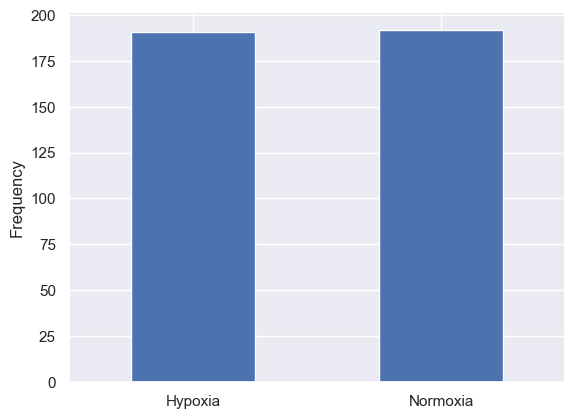

In [592]:
hypo_count = 0 
norm_count = 0
for cell in df.columns:
  cell_new = cell.replace('"', '')
  if df_meta.loc[cell_new, 'Condition'] == 'Hypo':
    hypo_count += 1
  else:
    norm_count += 1

s = pd.Series({"Hypoxia" : hypo_count, "Normoxia" : norm_count})
s.plot.bar(rot = 0)

plt.ylabel("Frequency")
plt.show()

From the histogram above it is clear that the conditions are balanced among the samples.

### Correlation

Regarding correlation, we start by looking at correlation between features, so  between cells based on the genes. <br>
We will plot a heatmap of the correlation matrix, with light and dark shades of red representing negative and positive correlations, respectively.





In [593]:
# # Compute the correlation matrix for all pairs of cells based on genes
# corr_matrix_n = df.corr() # pairwise correlation -> linear corr

# # Plot a heatmap of the correlation matrix
# sns.heatmap(corr_matrix_n, cmap="coolwarm", center=0, xticklabels=False, yticklabels=False)
# midpoint = (corr_matrix_n.values.max() - corr_matrix_n.values.min()) /2 + corr_matrix_n.values.min()
# plt.title("Correlation Matrix - features")
# plt.show()

From the plot, we can see that the dark red color represents high correlation between two cells, which means that the cells have similar gene expression profiles; this could indicate that they have a similar cellular function or that they are part of the same cell population. <br>
Since we notice that the minimum correlation between cells is negative we want to further invesztigate that.

Next we plot the frequency of the correlation matrix coefficients. Note: for the histogram we considered only the elements of the upper triangle of the correlation matrix because the uppare and lower triangles are simteric and in this was we don't compute the same thing twice.

In [594]:
# upper_triangular = np.triu(corr_matrix_n, k=1).flatten() 

# plt.hist(upper_triangular, bins=50, color='blue')
# plt.xlabel('Correlation Coefficient')
# plt.ylabel('Frequency')
# plt.title('Frequency of occurance of correlation coefficients')
# plt.show()

We can notice that there are a lot of cells which are weakly correlated and we want to futher investigate that. Our first assumption is that the reason behind it is that those cells have all 0 entries.

add the cells that are the least correlated with the othr cells !!!!!!!!!

In [595]:
# num_zero_cols = (df == 0).sum(axis=0)
# all_zero_cols = num_zero_cols[num_zero_cols == len(df)]
# print(f"Columns with all 0 entries:\n{all_zero_cols}")

Since that is not the case, according to the standard thresholds we want to check the intensity of correlations as follows: <br>
* 0.00-0.19 “very weak” <br>
* 0.20-0.39 “weak” <br>
* 0.40-0.59 “moderate” <br>
* 0.60-0.79 “strong” <br>
* 0.80-1.0 “very strong” <br>

In [596]:
# corr_df = df.corr()

# no_corr = list(corr_df[(corr_df == 0)].stack().index)
# very_weak = list(corr_df[(corr_df > 0) & (corr_df <= 0.19)].stack().index)
# weak = list(corr_df[(corr_df >= 0.2) & (corr_df <= 0.39)].stack().index)
# moderate = list(corr_df[(corr_df >= 0.4) & (corr_df <= 0.59)].stack().index)
# strong = list(corr_df[(corr_df >= 0.6) & (corr_df <= 0.79)].stack().index)
# very_strong = list(corr_df[(corr_df >= 0.8) & (corr_df <= 1)].stack().index)

# print('no_corr')
# print(no_corr)
# print('very_weak')
# print(very_weak)
# # print('weak')
# # print(weak)
# # print('moderate')
# # print(moderate)
# # print('strong')
# # print(strong)
# # print('very_strong')
# # print(very_strong)

We proceed by plotting the distribution of the cells that have very low coefficient correlation.

In [597]:
### THE PLOT TAKES TOO LONG IDK WHAT TO DO ###
# cells = [cell for pair in very_weak for cell in pair]

# # selected_cols = df[cells]

# fig, axes = plt.subplots(ncols=len(cells), figsize=(16,4))
# for i, cell in enumerate(cells):
#     sns.violinplot(x=df[cell], ax=axes[i], palette="Set3", cut=0)
#     axes[i].set_title(cell)
#     axes[i].set_xlabel('')
    
# plt.tight_layout()
# plt.show()

////// I HAVE TO ASK PROF ABOUT STH BEFORE I PUT IT ////////

VIFs (Varience Inflation Factor) measure the correlation among independent variables in least squares regression models. This type of correlation is refered to as multicollinearity. Calculating it will help us to chose which features to include in our model. <br>
If the VIF value is higher than 10, it is usually considered to have a high correlation with other independent variables; value of 1 indicates no correlation whatsoever.

In [598]:
# from statsmodels.stats.outliers_influence import variance_inflation_factor
# vif_df = pd.DataFrame()

# # Calculate the VIF for each feature
# vif_df['feature'] = df.columns
# vif_df['VIF'] = [variance_inflation_factor(df.values, i) for i in range(df.shape[1])]

# # Print the VIF values
# print(vif_df)

In [599]:
# cell_list_vif = vif_df.loc[vif_df['VIF'] >= 10, 'feature'].tolist()
# print(cell_list_vif)

Here we have a list of features for which VIF >= 10. When independent variables are highly correlated, change in one variable would cause change to another and so the model results fluctuate significantly and it leads to model being unstable. In order to avoid multicolinearity in the regression model we'll use PCA.

Now we plot the correlation matrix for gene. We expect that the genes which appear many times have high correlation with other genes.

In [600]:
# corr_matrix_genes = df.T.corr(method='pearson')

# # Plot the correlation matrix as a heatmap
# sns.heatmap(corr_matrix_genes, cmap='Blues', center=0, xticklabels=False, yticklabels=False)
# plt.title("Correlation Matrix - genes")
# plt.show()

We again plot the frequency to see zthe values of the correlation coefficient better.

In [601]:
# upper_triangular_genes = np.triu(corr_matrix_genes, k=1).flatten() 

# plt.hist(upper_triangular_genes, bins=50, color='blue')
# plt.xlabel('Correlation Coefficient - genes')
# plt.ylabel('Frequency')
# plt.title('Frequency of ocurance of correlation coefficients - genes')
# plt.show()

Clearly many genes are not in correaltion meaning that the gene expression is independent among the genes. <br>
We calculate VIF for genes.

In [602]:
# vif_df_genes = pd.DataFrame()
# df_t = df.transpose()
# # Calculate the VIF for each feature
# vif_df_genes['feature'] = df_t.columns
# vif_df['VIF'] = [variance_inflation_factor(df_t.values, i) for i in range(df_t.shape[1])]

# # Print the VIF values
# print(vif_df_genes)

We then proceed to print the top 10 correlated cell pairs based on the correlation coefficient. \\
We use the unstack method of the correlation matrix to convert it to a long-format table with three columns: the row index (cell A), the column index (cell B), and the correlation coefficient between A and B. We then filter out self-correlations, and sort the remaining pairs by correlation coefficient in descending order. \\
The indices on the left indicate the position of each pair of correlated cells in the correlation matrix, starting from 0 for the first pair, 1 for the second pair, and so on.

### Outliers

We can try to identify the outliers in our dataset by computing the interquartile range, which is a standard approach for detecting outliers. This involves calculating the difference between the 75th and 25th percentile of the data. Any data point that falls outside the range of 1.5 times the interquartile range below the 25th percentile or above the 75th percentile is considered an outlier. We can then try to remove these outliers from our dataset and analyze the result.

In [603]:
Q1 = df.quantile(0.25)
Q3 = df.quantile(0.75)
IQR = Q3 - Q1
print(IQR)

"output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam"    17.0
"output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam"     0.0
"output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam"     5.0
"output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam"       0.0
"output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam"       7.0
                                                              ... 
"output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam"     9.0
"output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam"    27.0
"output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam"    30.0
"output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam"    38.0
"output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"    33.0
Length: 383, dtype: float64


In [604]:
df.describe()

,"""output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A7_Hypo_S25_Aligned.sortedByCoord.out.bam""",...,"""output.STAR.4_H14_Hypo_S383_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H1_Norm_S355_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H2_Norm_S356_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"""
count,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,...,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000
mean,40.869330,0.012268,86.549356,1.025933,14.549749,56.284741,75.492556,62.847195,67.482078,2.243571,...,17.384545,42.133508,34.736302,32.775682,22.020563,17.461209,49.305086,61.623226,68.375769,62.930976
std,466.002411,0.207857,1037.224285,6.101112,123.877800,503.913891,430.735604,520.491980,459.973686,25.465612,...,193.275011,256.933843,680.390121,300.478924,153.536760,198.304138,359.560626,541.185241,637.290526,786.164389
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,17.000000,0.000000,5.000000,0.000000,7.000000,23.000000,39.000000,35.000000,38.000000,1.000000,...,9.000000,30.000000,0.000000,17.000000,12.000000,9.000000,27.000000,30.000000,38.000000,33.000000
max,46744.000000,14.000000,82047.000000,289.000000,10582.000000,46856.000000,29534.000000,50972.000000,36236.000000,1707.000000,...,17800.000000,23355.000000,81952.000000,29540.000000,12149.000000,19285.000000,28021.000000,40708.000000,46261.000000,68790.000000


To get a more detailed understanding, let us plot the distribution of the genes for some random cell, using a boxplot. This way we can get more details about the median, the upper and lower quartiles, and the minimum and maximum values. The box itself represents the interquartile range (IQR), which is the range of the middle 50% of the data.

<Axes: xlabel='"output.STAR.3_E11_Hypo_S233_Aligned.sortedByCoord.out.bam"'>

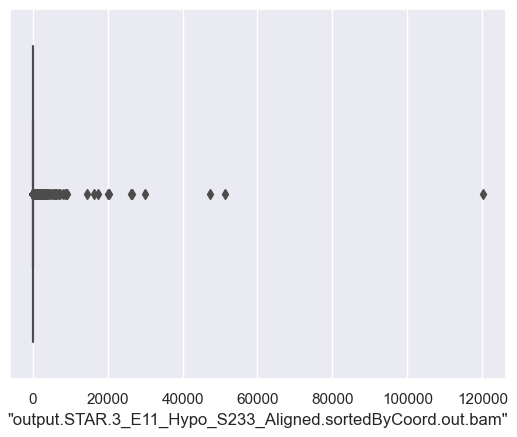

In [605]:
cells = list(df.columns)
random_cell = np.random.choice(len(cells))
sns.boxplot(x=df[cells[random_cell]])

A violin plot can be useful in this case because it provides a more informative visualization of the distribution of gene expression values than a simple box plot. Indeed, it also shows the shape of the distribution, which can be especially useful when working with high-dimensional data, such as gene expression data, where there are many genes and it can be difficult to get a sense of the overall distribution of expression values. Additionally, a violin plot can be used to compare the distributions of different groups, such as different cell types or experimental conditions.

<Axes: xlabel='"output.STAR.3_E11_Hypo_S233_Aligned.sortedByCoord.out.bam"'>

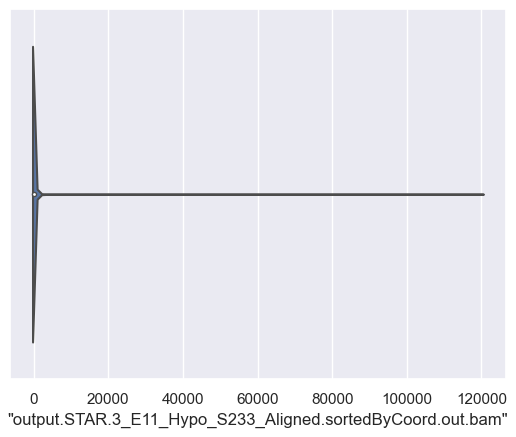

In [606]:
sns.violinplot(x=df[cells[random_cell]])

Moreover, we can plot the violin plot of 50 random features, which allows to get a broader view of the data, as well as any cells that exhibit a high degree of sparsity (i.e., contain mostly zero values). Additionally, this approach can help identify any patterns or trends in the data that may not be apparent when looking at single data points.

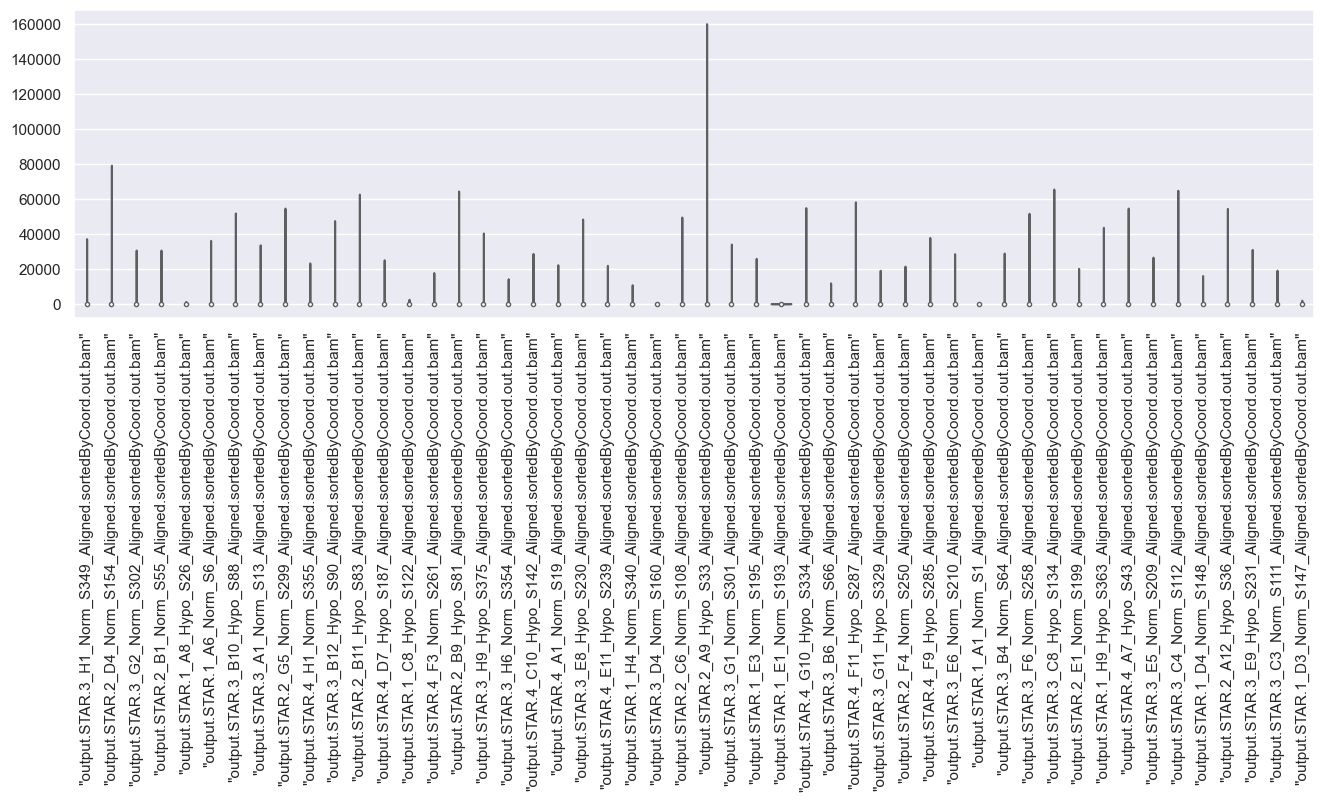

In [607]:
n_cells = 50
random_cells = np.random.choice(df.columns, size=n_cells, replace=False)

plt.figure(figsize=(16,4))
violin_plot = sns.violinplot(data=df[random_cells], palette="Set3", cut=0)
plt.setp(violin_plot.get_xticklabels(), rotation=90)
plt.show()

Let's attempt to remove outliers by using the interquartile range method. As a best practice in exploratory data analysis, it's recommended to create a new dataset for any transformations or filtering. This will ensure that the original dataset remains intact and can be used later if needed.

In [608]:
df_no_outliers = df[~((df < (Q1 - 1.5 * IQR)) |(df > (Q3 + 1.5 * IQR))).any(axis=1)]
df_no_outliers.shape
df_no_outliers.head(3)

,"""output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A7_Hypo_S25_Aligned.sortedByCoord.out.bam""",...,"""output.STAR.4_H14_Hypo_S383_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H1_Norm_S355_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H2_Norm_S356_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"""
"""MIR6859-1""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""CICP3""",0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
"""FAM87B""",0,0,0,0,0,0,0,0,2,0,...,0,1,0,0,0,0,0,0,0,0


Let us look at our dataset and plots again, for the dataset with outliers removed.

In [609]:
df_no_outliers.describe()

,"""output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A11_Hypo_S29_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A12_Hypo_S30_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A1_Norm_S1_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A7_Hypo_S25_Aligned.sortedByCoord.out.bam""",...,"""output.STAR.4_H14_Hypo_S383_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H1_Norm_S355_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H2_Norm_S356_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"""
count,6424.000000,6424.0,6424.000000,6424.0,6424.000000,6424.000000,6424.000000,6424.000000,6424.000000,6424.000000,...,6424.000000,6424.000000,6424.0,6424.000000,6424.000000,6424.000000,6424.000000,6424.000000,6424.000000,6424.000000
mean,0.110367,0.0,0.064134,0.0,0.076276,0.249377,0.341065,0.289228,0.391345,0.004981,...,0.064290,0.339508,0.0,0.177771,0.109122,0.119240,0.440380,0.229919,0.301370,0.185866
std,1.199197,0.0,0.595480,0.0,0.560607,1.980777,2.192926,1.792898,2.853749,0.080710,...,0.495103,2.236539,0.0,1.161355,0.809844,0.750801,3.122572,1.992255,2.615971,1.513244
min,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,41.000000,0.0,12.000000,0.0,15.000000,56.000000,50.000000,49.000000,62.000000,2.000000,...,11.000000,51.000000,0.0,25.000000,17.000000,21.000000,66.000000,53.000000,65.000000,51.000000


<Axes: xlabel='"output.STAR.3_E11_Hypo_S233_Aligned.sortedByCoord.out.bam"'>

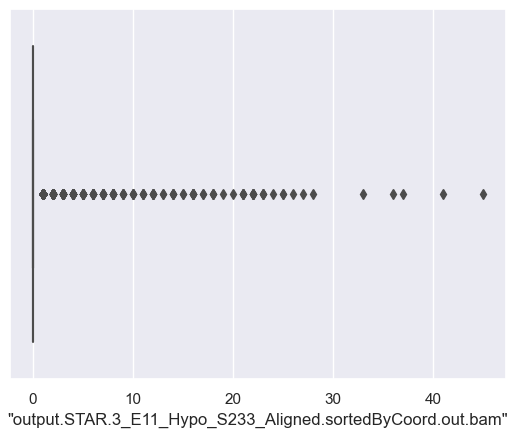

In [610]:
sns.boxplot(x=df_no_outliers[cells[random_cell]])

<Axes: xlabel='"output.STAR.3_E11_Hypo_S233_Aligned.sortedByCoord.out.bam"'>

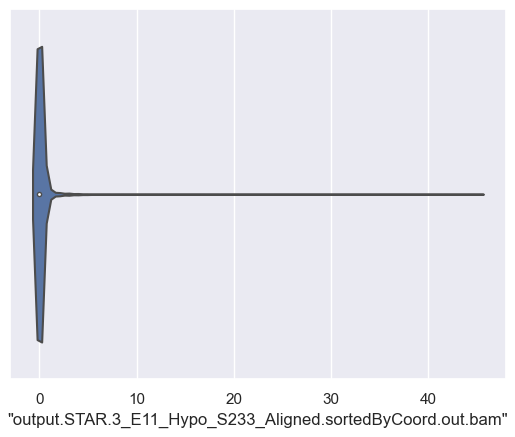

In [611]:
sns.violinplot(x=df_no_outliers[cells[random_cell]])

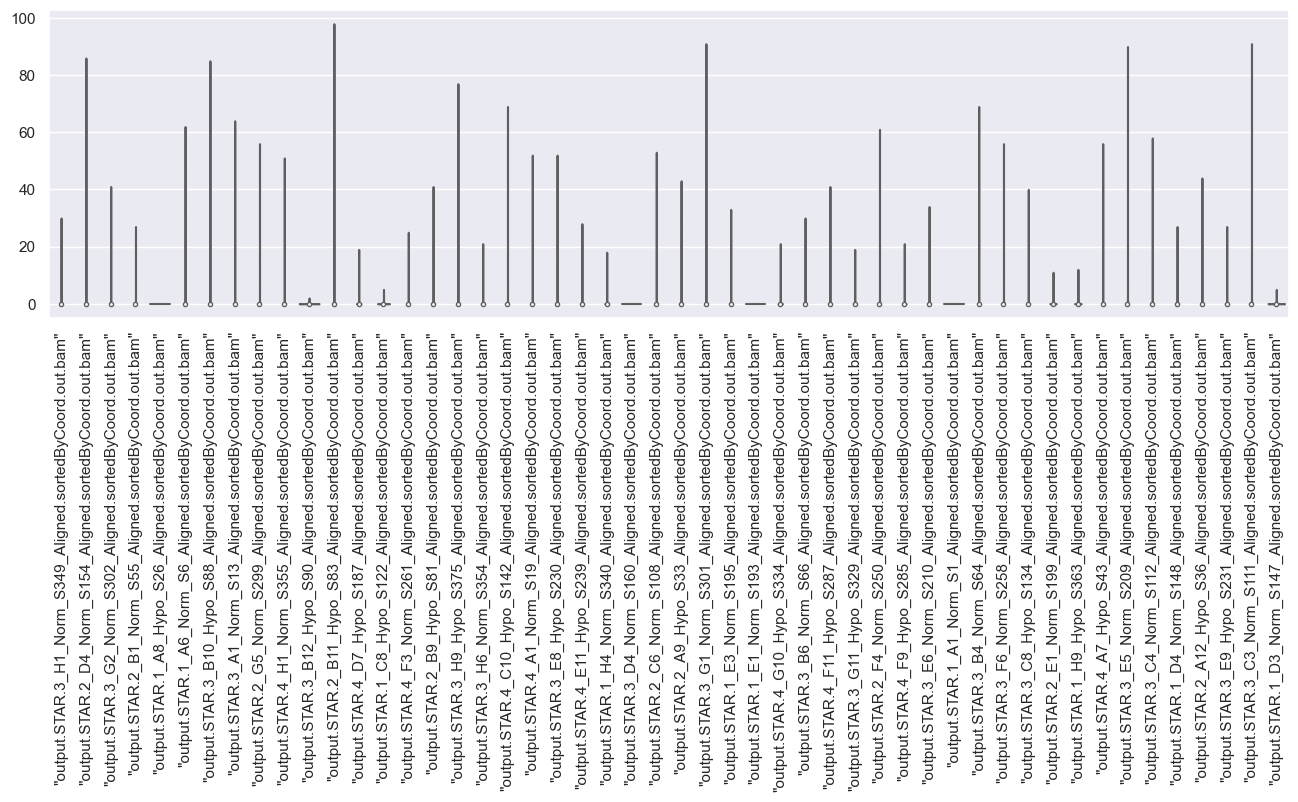

In [612]:
plt.figure(figsize=(16,4))
violin_plot = sns.violinplot(data=df_no_outliers[random_cells], palette="Set3", cut=0)
plt.setp(violin_plot.get_xticklabels(), rotation=90)
plt.show()

The current situation is not ideal as we are left with mainly zeros after removing the outliers. Simply removing the outliers won't solve the problem as many genes or features will still have a value of 0, which would lead to loss of information. Therefore, a different approach is needed, as the outliers appear to be the values that contain important information in this particular case. \
\
Therefore, it is the data's evident sparsity (i.e. the huge number of zeros, representing not expressed genes) to be giving more importance to outliers (representing genes with high expression). \
\
It is exactly the analysis of these highly-expressed genes that will lead to remarkable conclusions: genes with high expression in some cells are likely to be important in driving the biological processes that lead to cancer development and progression. These genes may represent key oncogenic drivers or tumor suppressors that are dysregulated in cancer cells. By identifying these highly expressed genes and understanding their functions, we can gain insights into the underlying biology of cancer.

### Sparsity


Sparsity is a measure of the proportion of zero values in a dataset or matrix. It is typically calculated as the number of zero elements divided by the total number of elements in the dataset or matrix. \
\
The sparsity value of this data frame indicates the proportion of cells in the data frame that are filled with non-zero values. A value of 1 indicates that all cells contain non-zero values, while a value closer to 0 indicates that a larger proportion of cells are zero. \
\
We can use a heatmap to visualize the sparsity of the dataset: here, the zero values in the dataframe are displayed as white cells and the non-zero values are displayed as black cells. The more white cells there are, the sparser the dataframe is.

<Axes: >

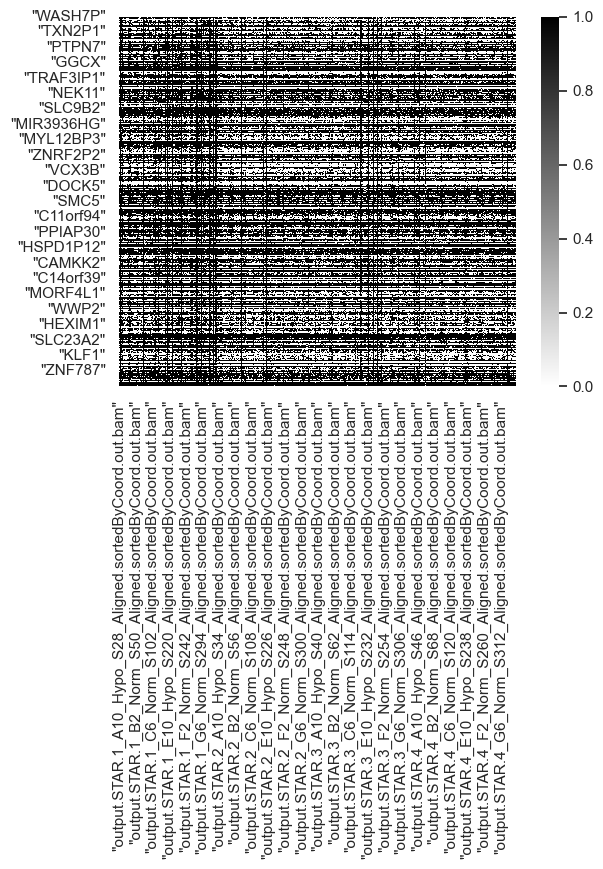

In [613]:
sns.heatmap(df == 0, cmap='binary')

It is remarkable how some rows are almost entirely white: this reveals that certain genes are not expressed in a majority of the cells, indicating that the biological function encoded by those genes may not be necessary for those particular cells. This could include the production of certain proteins, activation of metabolic pathways or regulation of specific gene expressions. \
\
Since there is a great amount of white cells in the heatmap, it is better to proceed with a more quantitative representation of sparsity. \
We can do that by computing the percentage of zeros in the dataframe.

In [614]:
zeros_count = (df == 0).sum().sum()
total_non_missing_values_count = df.count().sum()
zeros_percentage = (zeros_count / total_non_missing_values_count) * 100

print(f"Zeros percentage: {zeros_percentage:.2f}%")

Zeros percentage: 60.17%


Hence, as the proportion of zeros is fairly high, our dataset is definitely sparse (with sparsity level of around 0.6). \
\
Using sparse matrix representation could definitely be an advantage. Indeed, due to the high sparsity level, using a sparse matrix representation could lead to significant memory and computational savings, as only the non-zero values are stored and operated on. This can result in faster processing times and reduced memory usage, which can be especially important since we have a large dataset.

In [615]:
sparse_df = csr_matrix(df.values) # Converts DataFrame into a CSR sparse matrix
print(sparse_df)

density = np.count_nonzero(sparse_df.toarray()) / np.prod(sparse_df.shape)
print(f"Sparsity: {1 - density:.2%}")

  (0, 20)	1
  (0, 49)	1
  (0, 72)	1
  (0, 85)	1
  (0, 106)	2
  (0, 126)	1
  (0, 127)	1
  (0, 133)	2
  (0, 158)	9
  (0, 166)	1
  (0, 170)	1
  (0, 171)	1
  (0, 186)	1
  (0, 189)	3
  (0, 195)	1
  (0, 199)	2
  (0, 209)	1
  (0, 210)	1
  (0, 218)	1
  (0, 228)	2
  (0, 235)	1
  (0, 270)	4
  (0, 276)	1
  (0, 292)	1
  (0, 314)	2
  :	:
  (22904, 334)	12
  (22904, 336)	2
  (22904, 337)	1
  (22904, 340)	2
  (22904, 341)	3
  (22904, 342)	1
  (22904, 345)	3
  (22904, 346)	1
  (22904, 347)	6
  (22904, 348)	5
  (22904, 350)	5
  (22904, 351)	5
  (22904, 352)	1
  (22904, 357)	1
  (22904, 358)	6
  (22904, 361)	4
  (22904, 363)	2
  (22904, 369)	1
  (22904, 371)	2
  (22904, 372)	1
  (22904, 376)	2
  (22904, 377)	1
  (22904, 379)	6
  (22904, 381)	1
  (22904, 382)	4
Sparsity: 60.17%


### Kurtosis and skewness

\
When exploring the distribution of a dataset, it is important to consider summary statistics beyond just the mean and standard deviation. Skewness and kurtosis are two such measures that can provide additional insight into the shape of the distribution. \
\
Skewness measures the degree of asymmetry in the distribution, with positive skewness indicating a longer tail to the right and negative skewness indicating a longer tail to the left (with a value of 0 indicating a perfectly symmetrical distribution). \
\
Kurtosis, on the other hand, measures the degree of peakedness of the distribution, with high kurtosis indicating a more peaked distribution and low kurtosis indicating a flatter distribution. A value of 3 indicates a normal distribution, values less than 3 indicate flatter distributions (platykurtic), and values greater than 3 indicate more peaked distributions (leptokurtic).

Text(0.5, 0, 'Skewness of single cells expression profiles - original df')

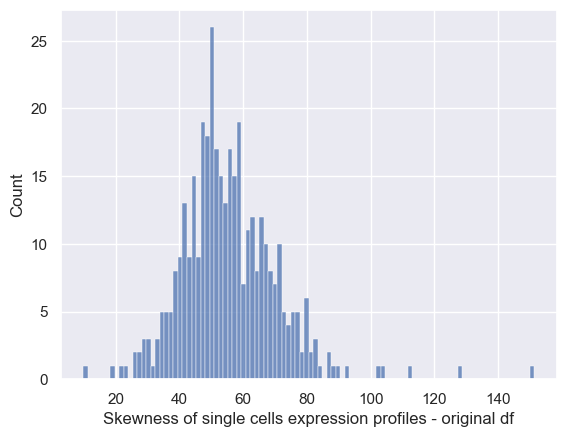

In [616]:
from scipy.stats import kurtosis, skew

col_num = np.shape(df)[1]
df_skew_cells = []

for i in range(col_num):      
     df_skew_cells += [df[cells[i]].skew()]
sns.histplot(df_skew_cells, bins=100)
plt.xlabel('Skewness of single cells expression profiles - original df')

Text(0.5, 0, 'Kurtosis of single cells expression profiles - original df')

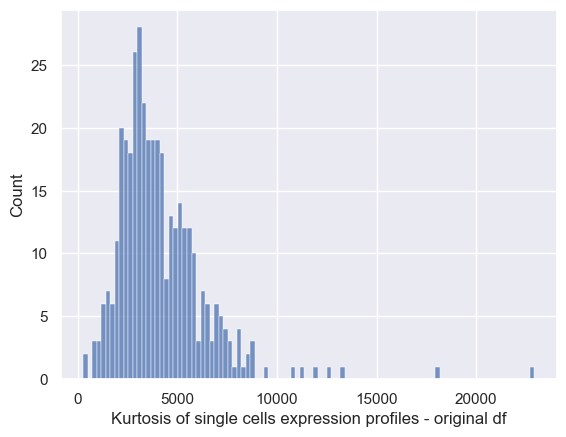

In [617]:
df_kurt_cells = []
for i in range(col_num) :     
    df_kurt_cells += [df[cells[i]].kurt()]
sns.histplot(df_kurt_cells, bins=100)
plt.xlabel('Kurtosis of single cells expression profiles - original df')

The resulting histograms show the distribution of the skewness and kurtosis values across all cells, allowing us to get a sense of the overall shape of the gene expression profiles in the dataset. \
It is clear how the skewness histogram is right skewed and the kurtosis histogram is leptokurtic, indicating that many cells have highly variable expression profiles with both high peaks and long tails. \
\
For comparison, here are skewness and kurtosis for a normal distribution.

In [618]:
xnorm = np.random.normal(0, 2, 10000000)   # Create random values based on a normal distribution

print(f"Excess kurtosis of normal distribution: {kurtosis(xnorm)}")
print(f"Skewness of normal distribution: {skew(xnorm)}")

Excess kurtosis of normal distribution: 0.0005413767872934905
Skewness of normal distribution: 0.0005001601762000855


Then, the skewness and kurtosis values of the dataset suggest a highly non-normal distribution, as they greatly exceed the values expected for a normal distribution.

### Non-zero gene expression

We now want to investigate the genes with non-zero expression. 

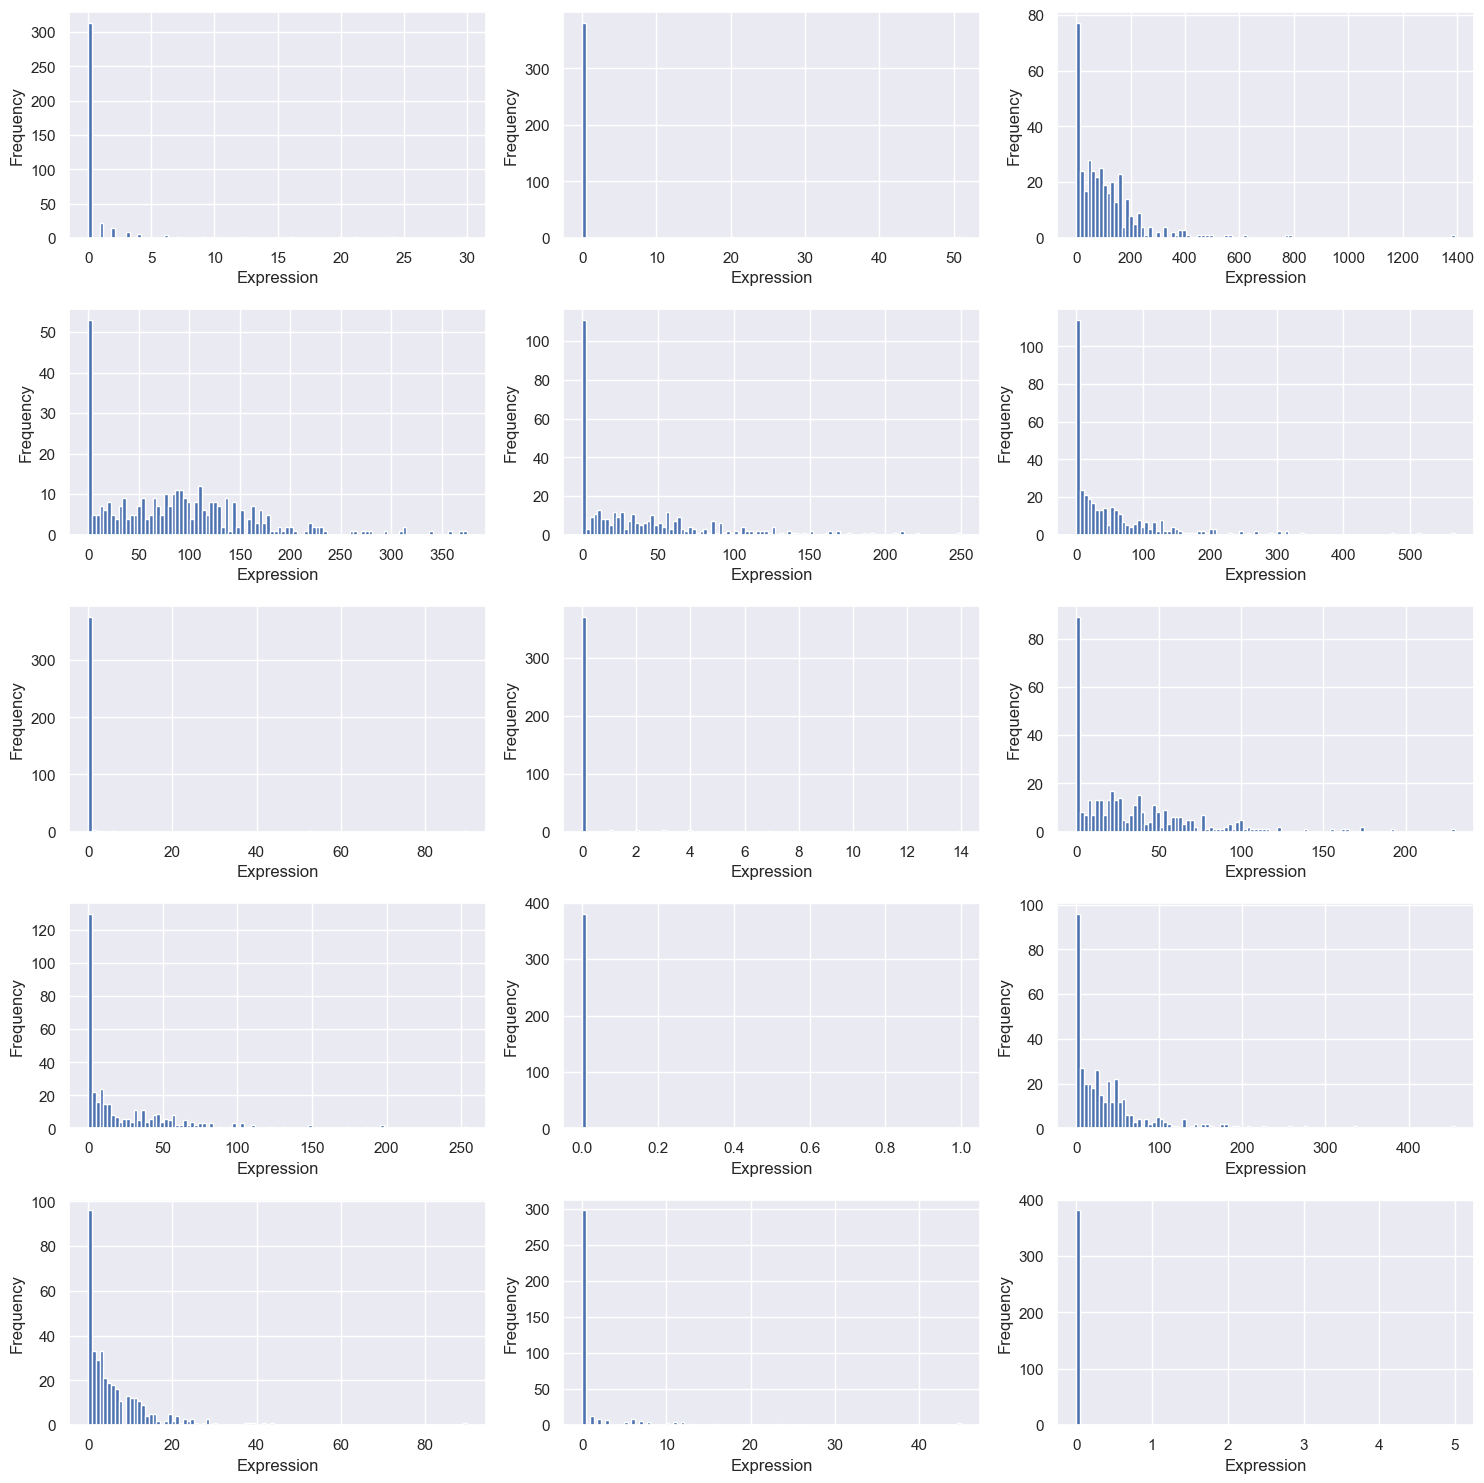

In [619]:
data = df.T
data = data.loc[(data!=0).any(axis=1), :]
genes = np.random.choice(data.columns, size=15, replace=False)
fig, ax = plt.subplots(nrows=5, ncols=3, figsize=(15,15))
for i, gene in enumerate(genes):
    gene_data= data[gene]
    row_num= i//3
    col_num= i%3
    ax[row_num, col_num].hist(gene_data, bins=100)
    ax[row_num, col_num].set_xlabel('Expression')
    ax[row_num, col_num].set_ylabel('Frequency')
fig.tight_layout()
plt.show()

We would expect to observe a bimodal behaviour, since it is common in the distribution of gene expression levels, however we notice a unimodal behaviour in all of the cases (meaning that the data has a single peak). This is probably due to various biological factors. From the plots we can observe that the data doesn't present any upper limit for expression, and that it follows either a Negative Binomial or Poisson distribution (it depends on wether the mean and the variance coincide or not). We therefore now proceed by analysing the relationship between the mean and the variance by plotting them.

Text(0, 0.5, 'Variance')

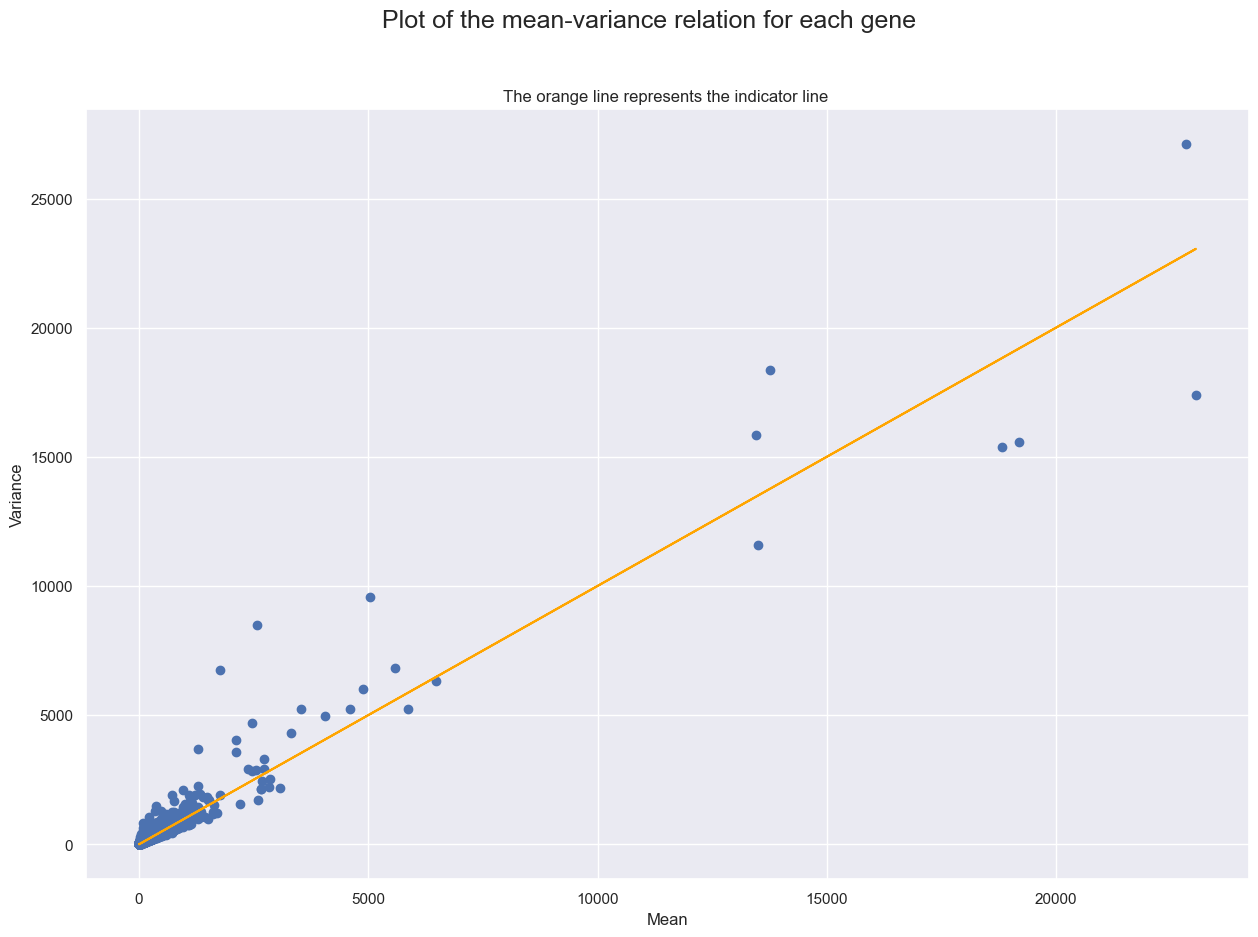

In [620]:
mean_vector = df.T.describe().iloc[1,:]
var_vector = df.T.describe().iloc[2,:]
plt.figure(figsize=(15, 10))
plt.scatter(mean_vector, var_vector)
plt.plot(mean_vector, mean_vector, color = "orange")
plt.title("The orange line represents the indicator line ", fontsize = 12)
plt.suptitle("Plot of the mean-variance relation for each gene", fontsize = 18)
plt.xlabel("Mean")
plt.ylabel("Variance")

We can observe a linear relation between mean and variance, therefore we can conclude that the data follows a Poisson distribution.

## Filtering - Quality control


\
At this point we aim to determine whether the distribution of the total reads among cells is normal. This is done to asses the quality of the data and make sure there are no systemic biases as the total read count can be affected by technical factors, something that would need to be corrected. \
\
We use the Shapiro-Wilk test. \
\
[The Shapiro-Wilk test can be used to test for normality of the data. It tests the null hypothesis that a sample comes from a normally distributed population. It does not specifically test for normality of the measurement error, but rather for normality of the entire dataset. However, if the measurement error is the main contributor to non-normality in the data, then the Shapiro-Wilk test may indirectly detect non-normality in the measurement error.] \
\
[a 'read' is a single sequence of neucleotides obtained from a single fragment of RNA during sequencing (the process of RNA sequencing involves breaking up the RNA molecules in a sample into short fragments, sequencing these fragments, and then aligning the resulting sequences to a reference genome or transcriptome to identify the genes that were expressed in the sample), the number of reads for each gene can be used as a proxy for its expression level, with more reads indicating higher expression \
\'total read count' refers to the total number of reads obtained from an RNA-seq experiment for a given sample] \
\
*note: also mention that two other types of normalization were applied to reduce potential problems with total read counts, including extracting the same amount of RNA from each sample in the lab and adjusting the sequencing runs to obtain similar numbers of counts for each sample.

In [621]:
from scipy.stats import shapiro

total_counts = np.sum(df, axis=0) # sum the counts across all genes for each cell

# perform Shapiro-Wilk test to check for normality
stat, p = shapiro(total_counts)

if p > 0.05: # if p-value is greater than 0.05, we cannot reject the null hypothesis that the data is normally distributed
    print("Total read counts follow a normal distribution (p={:.3f})".format(p))
else:
    print("Total read counts do not follow a normal distribution (p={:.3f})".format(p))

Total read counts do not follow a normal distribution (p=0.000)


Now we want to visualize this result to better understand how we need to filter our data.

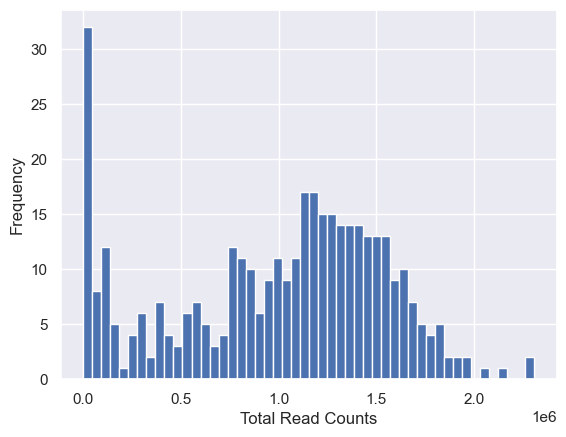

In [622]:
# Create a histogram of the total read counts
plt.hist(total_counts, bins=50)

# Set the x-axis label
plt.xlabel('Total Read Counts')

# Set the y-axis label
plt.ylabel('Frequency')

# Show the plot
plt.show()

In [623]:
df_filtered = df.loc[:, total_counts >= .25e6]

Another standard analysis step is to filter out low quality cells, cells that may have been damaged during the experiment (have a low number of expressed genes) and that could affect the quality of the data.

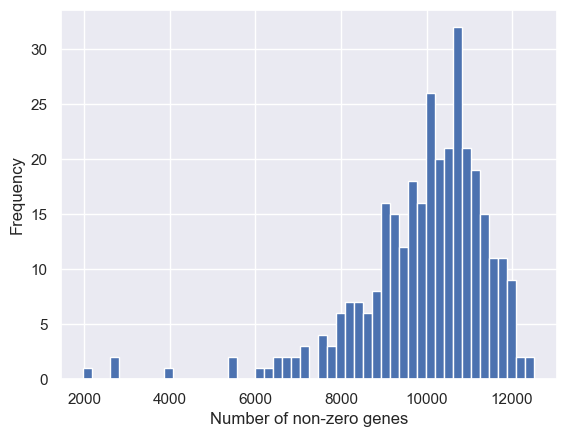

In [624]:
# count number of non-zero genes for each cell
nonzero_counts = np.count_nonzero(df_filtered, axis=0)

# plot histogram
plt.hist(nonzero_counts, bins=50)
plt.xlabel('Number of non-zero genes')
plt.ylabel('Frequency')
plt.show()

In [625]:
df_filtered = df_filtered.loc[:, nonzero_counts >= 7500]

By looking at the graphs we set thresholds based on which we can filter out cells to eliminate unwanted variation/noise and the effects of human errors.

In [626]:
df_filtered.shape

(22905, 305)

## Normalization

Now we want to work on normalizing our data so that any systematic differences in sequencing are removed and do not interfere with comparisons of the expression profiles between cells. The question that arises is how can we choose the normalization we apply/follow ?

We consider applying more than one normalization methods in order to compare our results and decide which is better suited for our analysis. The most common types of normalization for gene expression data are TPM and Library Size Normalization, so we look at these first.

TPM (Transcripts Per Million) normalization: this method scales the counts for each gene by the total number of reads in the library and the length of the gene (appropriate if you want to compare expression levels between genes). Even if it is a common normalization for gene expression data, it is length-normalized meaning we cannot apply it since we do not have information about gene lengths.

In [627]:
import random

df_filtered_copy = df_filtered.copy()
rdn_gene = random.randrange(df_filtered.shape[0])

Library size normalization: this method involves dividing the raw read counts of each sample/cell by the total number of reads in that sample, and then multiplying by a scaling factor (such as the mean or median library size) to ensure that the total read counts across all samples are equal. This method is useful when comparing gene expression levels across samples with different total read counts, as is our case.

Note: 'library size' is defined as the total sum of counts across all genes for each cell and its specific value can be assumed to scale any cell-specific biases

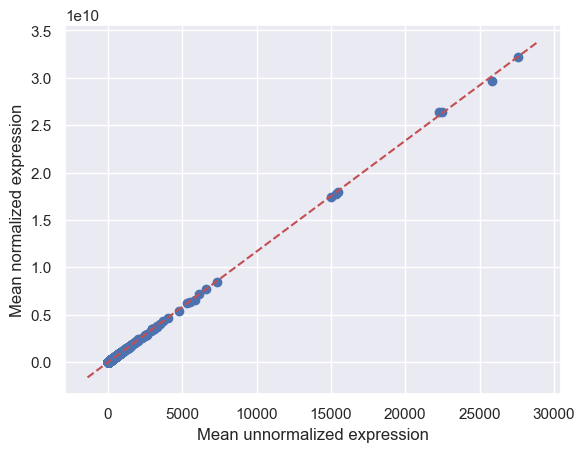

In [628]:
# library size normalization

# Calculate the library size for each cell
lib_size = df_filtered.sum(axis=0)

# Calculate scaling factor for each cell
scaling_factor = lib_size / lib_size.mean()

# Normalize the data using the scaling factor
df_normalized = (df_filtered / scaling_factor) * lib_size.mean()

# Calculate the mean expression level before normalization
mean_filtered = df_filtered.mean(axis=1)

# Calculate the mean expression level after normalization
mean_normalized = df_normalized.mean(axis=1)

#print(mean_filtered.shape)
#print(mean_normalized.shape)

# Create a scatter plot
#plt.scatter(df_filtered.iloc[rdn_gene, :], df_normalized.iloc[rdn_gene, :])    #*****CHECK*****
plt.scatter(mean_filtered, mean_normalized)
plt.xlabel('Mean unnormalized expression')
plt.ylabel('Mean normalized expression')

# Plot the diagonal line of slope 1
x = plt.xlim()
y = plt.ylim()
plt.plot(x, y, color='r', linestyle='--')
plt.show()

CPM (Counts Per Million) normalization: this method scales the raw counts by the library size of each sample, multiplied by a factor of 1,000,000 (1e6)

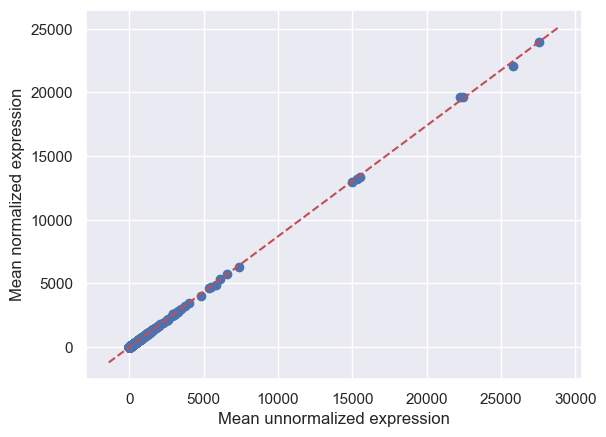

In [629]:
#CPM

# Calculate the total read count for each sample
total_reads = df_filtered_copy.sum(axis=0)

# Divide each read count in the DataFrame by corresponding total count and multiply by 1,000,000
cpm_df =  (df_filtered / total_reads) * 1e6

# Calculate the mean expression level before normalization
mean_filtered = df_filtered.mean(axis=1)

# Calculate the mean expression level after normalization
mean_normalized = cpm_df.mean(axis=1)



# Create a scatter plot
#print('Selected gene:', rdn_gene)
#print('Unnormalized expression:', df_filtered.iloc[rdn_gene, :])
#print('Normalized expression:', df_normalized.iloc[rdn_gene, :])
#plt.scatter(df_filtered_copy.iloc[rdn_gene, :], df_normalized.iloc[rdn_gene, :])
plt.scatter(mean_filtered, mean_normalized)
plt.xlabel('Mean unnormalized expression')
plt.ylabel('Mean normalized expression')
x = plt.xlim()
y = plt.ylim()
plt.plot(x, y, color='r', linestyle='--')
plt.show()

We can see a strong similarity between the graphs resulting from each normalization, which could make sense if dataset has relatively small variations in library sizes across cells.

In the scatter plot, each point represents a gene, and the x-coordinate is the mean expression level before normalization, while the y-coordinate is the mean expression level after normalization. By looking at the plot, we can interpret how well the normalization has worked. The points are tightly clustered around the diagonal line of slope 1 which indicates that the normalization was successful and has removed differences in library size between the samples.

Let us update the data set with the filtered and normalized data set.

In [630]:
cpm_df.describe()

,"""output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B10_Hypo_S76_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B11_Hypo_S77_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B12_Hypo_S78_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B4_Norm_S52_Aligned.sortedByCoord.out.bam""",...,"""output.STAR.4_H10_Hypo_S382_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H14_Hypo_S383_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H1_Norm_S355_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"""
count,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,...,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000
mean,43.658590,43.658590,43.658590,43.658590,43.658590,43.658590,43.658590,43.658590,43.658590,43.658590,...,43.658590,43.658590,43.658590,43.658590,43.658590,43.658590,43.658590,43.658590,43.658590,43.658590
std,497.806257,371.712947,390.872719,249.101501,361.574544,297.587197,452.899651,513.117161,393.481362,472.115398,...,556.545295,485.380233,266.233927,400.250590,304.406311,495.823564,318.383175,383.416868,406.916161,545.404361
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.694678,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,18.160220,21.004495,17.840494,22.554343,24.313745,24.584697,19.237790,19.800044,24.444837,19.331018,...,17.363791,22.602105,31.085892,22.644716,23.791539,22.502869,23.907917,21.254286,24.263367,22.893868
max,49934.195908,31752.795098,36344.963784,17079.999098,35409.148220,23443.449052,26441.030708,34692.152624,26564.097550,43775.090050,...,47409.901219,44701.941019,24200.367228,39348.524830,24086.950143,48218.647878,24811.990795,28840.649531,29538.095722,47723.308872


In [631]:
df = cpm_df.copy()

## Log-Transformation

We now want to analyse skewness and kurtosis of the normalized and filtered data set to check if they have improved.

Text(0.5, 0, 'Skewness of single cells expression profiles - original df')

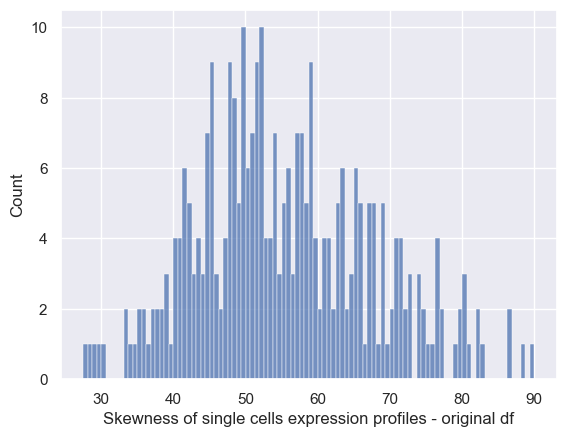

In [632]:
# skewness of normalized and filtered data set
cells_filt = df.columns
col_num = np.shape(df)[1]
df_skew_cells = []

for i in range(col_num):      
     df_skew_cells += [df[cells_filt[i]].skew()]
sns.histplot(df_skew_cells, bins=100)
plt.xlabel('Skewness of single cells expression profiles - original df')

Text(0.5, 0, 'Kurtosis of single cells expression profiles - original df')

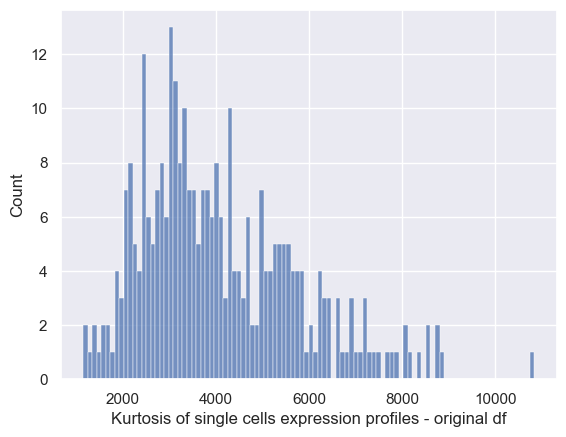

In [633]:
# kurtosis of normalized and filtered data set
df_kurt_cells = []
for i in range(col_num) :     
    df_kurt_cells += [df[cells_filt[i]].kurt()]
sns.histplot(df_kurt_cells, bins=100)
plt.xlabel('Kurtosis of single cells expression profiles - original df')

Since they are still pretty messy, we apply a logarithmic transformation, which is a potential solution to address the issue of skewed distribution of gene expression data. Using the logarithmic base 2 transformation is common as adding 1 to the data indicates doubling of the feature abundance (gene expression) and subtracting 1 indicates halving of the feature abundance. \
\
This transformation makes the changes in the feature abundance symmetric in both directions, so up-regulation and down-regulation of a gene with respect to a control is symmetrical. The transformed data can then be visualized using a boxplot to check if the distribution has become more normal and to identify any outliers.

In [634]:
df_log2 = np.log2(df+1)

In [635]:
df_log2.describe()

,"""output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B10_Hypo_S76_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B11_Hypo_S77_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B12_Hypo_S78_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B4_Norm_S52_Aligned.sortedByCoord.out.bam""",...,"""output.STAR.4_H10_Hypo_S382_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H14_Hypo_S383_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H1_Norm_S355_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"""
count,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,...,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000,22905.000000
mean,1.925585,2.184312,2.035665,2.208385,2.361747,2.239099,1.967943,2.008372,2.230206,1.988617,...,1.931032,2.193387,2.396681,2.135127,2.118243,2.134295,2.082141,2.034814,2.116059,2.092207
std,2.784815,2.812017,2.783784,2.830957,2.806257,2.838717,2.778069,2.734314,2.790238,2.798260,...,2.719070,2.762970,2.887091,2.832835,2.844716,2.793125,2.865390,2.786207,2.819348,2.766999
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.761012,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,4.260042,4.459726,4.235765,4.557921,4.661849,4.677209,4.338980,4.378515,4.669301,4.345611,...,4.198792,4.560844,5.003867,4.563446,4.631776,4.554765,4.638532,4.476011,4.658975,4.578569
max,15.607769,14.954641,15.149508,14.060105,15.111875,14.516959,14.690545,15.082363,14.697244,15.417855,...,15.532931,15.448082,14.562801,15.264059,14.556024,15.557333,14.598808,14.815866,14.850338,15.542437


In [636]:
df_log2.head()

,"""output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B10_Hypo_S76_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B11_Hypo_S77_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B12_Hypo_S78_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B4_Norm_S52_Aligned.sortedByCoord.out.bam""",...,"""output.STAR.4_H10_Hypo_S382_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H14_Hypo_S383_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H1_Norm_S355_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam"""
"""WASH7P""",0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,...,0.974276,0.000000,0.000000,1.221594,0.0,0.0,0.000000,0.77271,0.000000,0.760224
"""MIR6859-1""",0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0.000000,0.000000
"""WASH9P""",1.048409,0.0,0.828366,2.761959,0.761012,0.0,1.671797,1.797015,1.044617,0.0,...,1.550561,1.812024,1.025877,0.000000,0.0,0.0,0.914931,0.77271,1.829459,2.159877
"""OR4F29""",0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0.712384,0.000000
"""MTND1P23""",0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.000000,0.00000,0.000000,0.000000


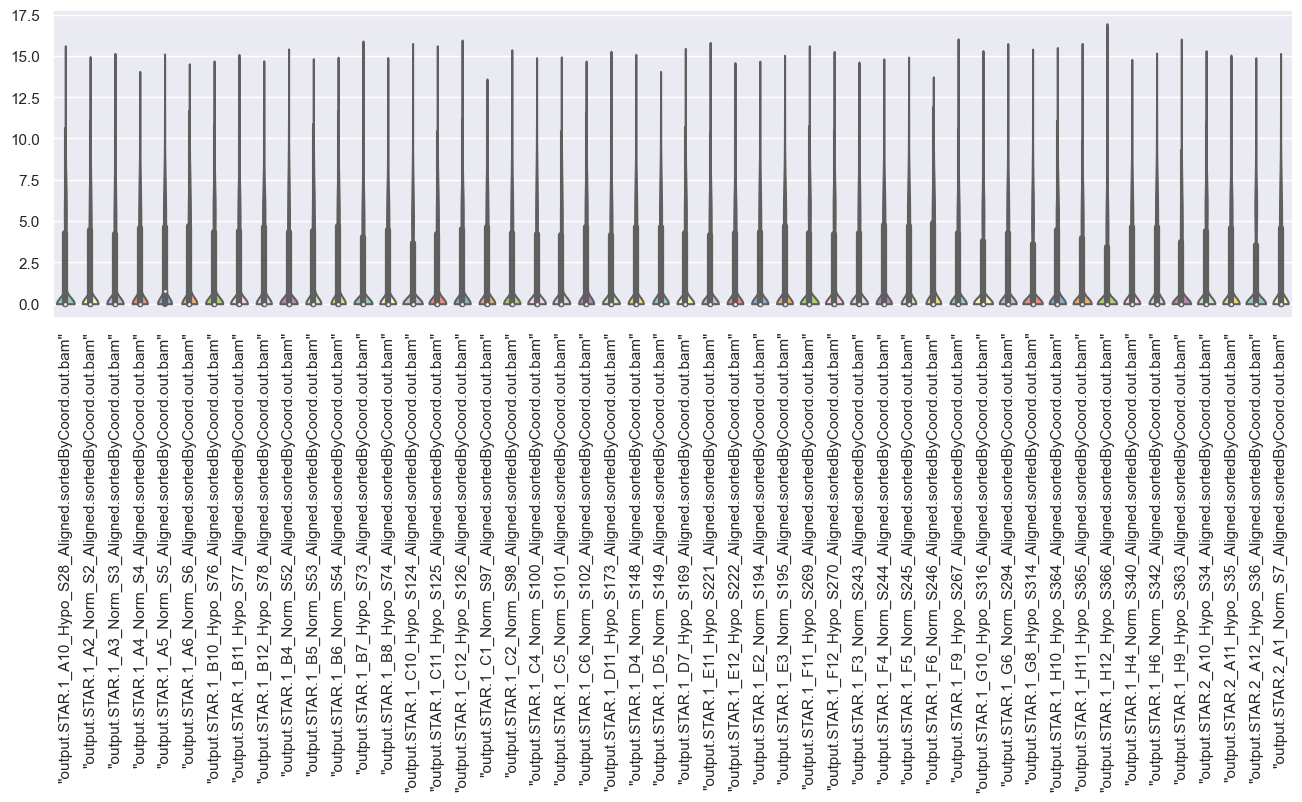

In [637]:
# df_plus = df + 1
# df_log2_plus = df_plus.apply(np.log2)

# Selecting part of the data, as the plots would otherwise take too long to generate
df_log2_small = df_log2.iloc[:, :50]
plt.figure(figsize=(16,4))
plot = sns.violinplot(data=df_log2_small, palette="Set3", cut=0)
plt.setp(plot.get_xticklabels(), rotation=90)
plt.show()

Text(0.5, 0, 'Skewness of single cells expression profiles - log2 df')

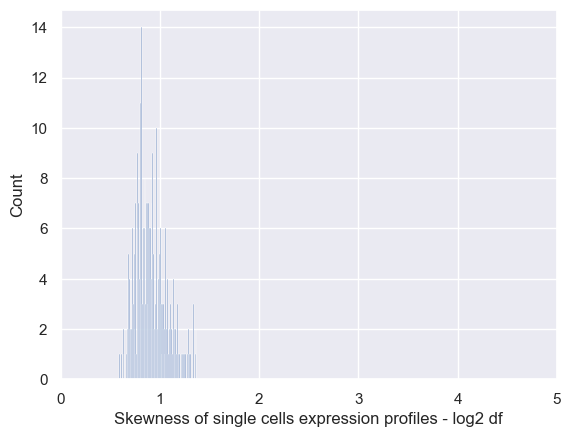

In [638]:
df_log2_skew = []
for i in range(col_num) :     
     v_df = df_log2[cells_filt[i]]
     df_log2_skew += [skew(v_df)]   
sns.histplot(df_log2_skew, bins=100)
plt.xlim(0, 5)
plt.xlabel('Skewness of single cells expression profiles - log2 df')

Text(0.5, 0, 'Kurtosis of single cells expression profiles - log2 df')

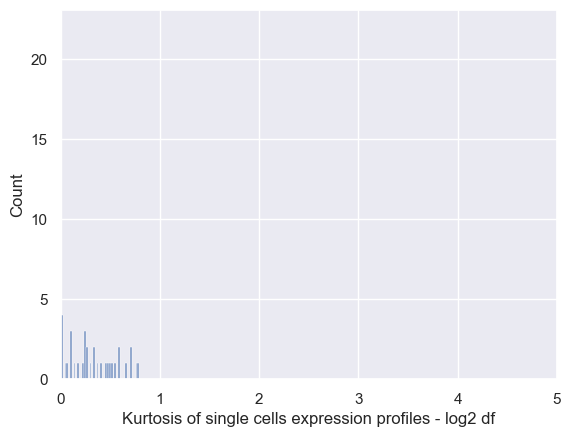

In [639]:
df_log2_kurt = []
for i in range(col_num) :     
     v_df = df_log2[cells_filt[i]]
     df_log2_kurt += [kurtosis(v_df)] 
sns.histplot(df_log2_kurt, bins=100)
plt.xlim(0, 5)
plt.xlabel('Kurtosis of single cells expression profiles - log2 df')

The values of skewness and kurtosis have improved (both being close to 0 for pretty much every cell), so we can keep this transformation for now.

In [640]:
df = df_log2.copy() # Using the logarithmic transformation of the data as our dataset from now on

In [641]:
stop

NameError: name 'stop' is not defined

## Feature selection

Feature selection can be applied to most of the models we will use later especially since we are dealing with high-dimensional datasets, or suspected irrelevant features.

Filter feature selection methods use statistical techniques to evaluate the relationship between each input variable and the target variable, and these scores are used as the basis to choose (filter) those input variables that will be used in the model. \
\
Since the input data is numerical, and the output is chategorical we choose ANOVA as feature selection method. 
We will use `f_classif` function from the sklearn.feature_selection module. \
Moreover, we set the parameter k of the `SelectKBest()` function to be equal to 3000 to be able to effectively compare our filtered data set with the given prefiltered data set (containing 3000 most important features). 

We will also check for genes that have constant expression across all samples. If there are some we will remove them since they do not provide any discriminatory information. 

In [ ]:
constant_features = df.index[df.T.var() == 0]
df = df.drop(constant_features, axis=0)
print(constant_features)

In [ ]:
from sklearn.feature_selection import SelectKBest, f_classif

conditions = []
for cell in df.columns:
  cell_new = cell.replace('"', '')
  if df_meta.loc[cell_new, 'Condition'] == 'Hypo':
    conditions.append("Hypoxia")
  else:
    conditions.append("Normoxia")

selector = SelectKBest(score_func=f_classif, k=3000)
selected_arr = selector.fit_transform(df.T, conditions)

selected_indices = selector.get_support(indices=True)
selected_features = df.T.columns[selected_indices]

df_selected = df.iloc[selected_indices]

print("Selected Features:", list(selected_features))



In [ ]:
df = df_selected.copy()

## Clustering

We want to investigate wether there are some clusters in the dataset therefore we proceed with the unsupervised clustering algorithm k-means. 

In [ ]:
#non_zero_cols = df.columns[df.sum() > 0]
#non_zero_df = df[non_zero_cols]

#reducer = umap.UMAP()
#embedding = reducer.fit_transform(non_zero_df.T)

# cluster with KMeans
#n_clusters = 5  # set number of clusters
#kmeans = KMeans(n_clusters=n_clusters, random_state=42)
#kmeans.fit(embedding)

# plot results
#import matplotlib.pyplot as plt
#import seaborn as sns

#fig, ax = plt.subplots(figsize=(10, 8))
#sns.scatterplot(
   # x=embedding[:, 0], y=embedding[:, 1],
    #hue=kmeans.labels_, palette=sns.color_palette('husl', n_clusters),
    #legend='full', alpha=0.8, ax=ax
#)
#ax.set_title('UMAP with KMeans Clustering')
#ax.legend(loc='lower right')
#plt.show()

In [ ]:
ciao

We obtain some well-separated clusters in the UMAP embadding, which could mean that the cells come from distinct subpopulations with different roles. Indeed with further investigations, for example by using Gene Set Enrichment Analysis (GSEA), we could identify the functions of the cells in the clusters. More precisely the mentioned technique allows to identify wether the cells present enriched genes, which are the ones that are overrepresented in a particular group of genes compared to their expected frequency in the genome. Enrichment analysis is indeed particularly useful in cancer research to identify gene sets that are differentially expressed or mutated in cancer cells compared to normal cells, and thus may be involved in the development or progression of cancer. 

### **T-test on the dataset we filtered and normalized**

In [642]:
df.head()
df.shape

(22905, 305)

In [643]:

hypo_cells = df.loc[:, df.columns.str.contains('Hypo')]
norm_cells = df.loc[:, df.columns.str.contains('Norm')]
print(hypo_cells.shape)
print(norm_cells.shape) # perform t-test on each gene
results = []
for gene in df.index:
    pval = ttest_ind(hypo_cells.loc[gene], norm_cells.loc[gene])[1]
    results.append(pval)

(22905, 144)
(22905, 161)


In [644]:
# add p-values as a new column to the dataframe
df['pvalue'] = results
print(results)
# filter for statistically significant genes
sig_genes = df.loc[df['pvalue'] < 0.05]


[0.39035587514635406, 0.03816071100190141, 0.00026614710430981783, 0.2555014416266825, 0.06973911599384497, 1.0743598078953082e-17, 8.756658378396885e-32, 7.096888391565807e-15, 0.001017227848646683, 2.0737125094109662e-74, 3.2727925923753896e-19, 0.4821873611566775, 0.18266220569654848, 0.05377439249688188, 0.6772455322293889, 0.16278151437821317, 0.020108268646512658, 0.0007524557572545139, 3.09382572686253e-11, 6.844491749828112e-19, 3.033039479209883e-08, 0.10383010632431168, 0.6824029757048229, 5.1204005484065724e-12, 3.8525155808802394e-13, 9.420769313562451e-08, 1.8036627251154487e-06, 1.491155931538062e-12, 0.20777032016131686, 0.19126802479656033, 9.420618318491482e-16, 1.3312801262284255e-16, 4.2800373039804083e-17, 0.030184605532730797, 2.187257913167411e-12, 0.06220008062255106, 0.6041826845873028, 7.141631764002341e-06, 0.8929915185306061, 5.724236943425863e-17, 4.630416546531335e-12, 0.025256219240902825, 0.0006131528697045539, 0.3444485306451436, 0.6649150126414867, 0.65

In [645]:
# create a new column called "significant gene" with default value "No"
df['significant gene'] = 'No'

# set the value of "significant gene" to "Yes" for rows with p-value < 0.05
df.loc[df['pvalue'] < 0.05, 'significant gene'] = 'Yes'

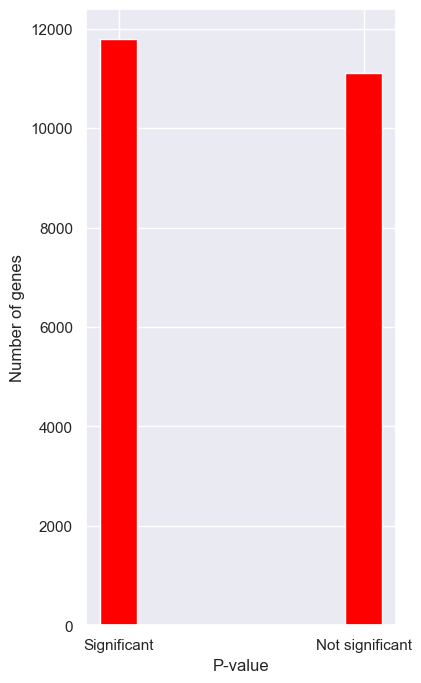

In [646]:
sig_count = (df['pvalue'] < 0.05).sum()

# plot bar chart
plt.figure(figsize=(4,8))
plt.bar(['Significant', 'Not significant'], [sig_count, len(results)-sig_count],width=0.15, color='red')
plt.xlabel('P-value')
plt.ylabel('Number of genes')
plt.show()

In [647]:
# Perform Bonferroni correction
bonferroni_results = multipletests(results, alpha=0.05, method='bonferroni')
df['bonferroni_pvalue'] = bonferroni_results[1]

# Identify significant genes using both methods
ttest_sig_genes = df[df['pvalue'] < 0.05]
bonferroni_sig_genes = df[df['bonferroni_pvalue'] < 0.05]


In [648]:
# Compare the number of significant genes
print("Number of significant genes identified by t-test: ", len(ttest_sig_genes))
print("Number of significant genes identified by Bonferroni correction: ", len(bonferroni_sig_genes))

Number of significant genes identified by t-test:  11801
Number of significant genes identified by Bonferroni correction:  5706


In [649]:
df.head()

,"""output.STAR.1_A10_Hypo_S28_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A2_Norm_S2_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A3_Norm_S3_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A4_Norm_S4_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A5_Norm_S5_Aligned.sortedByCoord.out.bam""","""output.STAR.1_A6_Norm_S6_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B10_Hypo_S76_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B11_Hypo_S77_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B12_Hypo_S78_Aligned.sortedByCoord.out.bam""","""output.STAR.1_B4_Norm_S52_Aligned.sortedByCoord.out.bam""",...,"""output.STAR.4_H3_Norm_S357_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H4_Norm_S358_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H5_Norm_S359_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H6_Norm_S360_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H7_Hypo_S379_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H8_Hypo_S380_Aligned.sortedByCoord.out.bam""","""output.STAR.4_H9_Hypo_S381_Aligned.sortedByCoord.out.bam""",pvalue,significant gene,bonferroni_pvalue
"""WASH7P""",0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,...,1.221594,0.0,0.0,0.000000,0.77271,0.000000,0.760224,0.390356,No,1.0
"""MIR6859-1""",0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.0,0.0,0.000000,0.00000,0.000000,0.000000,0.038161,Yes,1.0
"""WASH9P""",1.048409,0.0,0.828366,2.761959,0.761012,0.0,1.671797,1.797015,1.044617,0.0,...,0.000000,0.0,0.0,0.914931,0.77271,1.829459,2.159877,0.000266,Yes,1.0
"""OR4F29""",0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.0,0.0,0.000000,0.00000,0.712384,0.000000,0.255501,No,1.0
"""MTND1P23""",0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,...,0.000000,0.0,0.0,0.000000,0.00000,0.000000,0.000000,0.069739,No,1.0


                pvalue significant gene
"NDRG1"  3.590045e-124              Yes
"BNIP3"  2.479306e-117              Yes
"GAPDH"  5.006326e-115              Yes
"GPI"     6.881273e-99              Yes
"ALDOA"   6.816505e-94              Yes


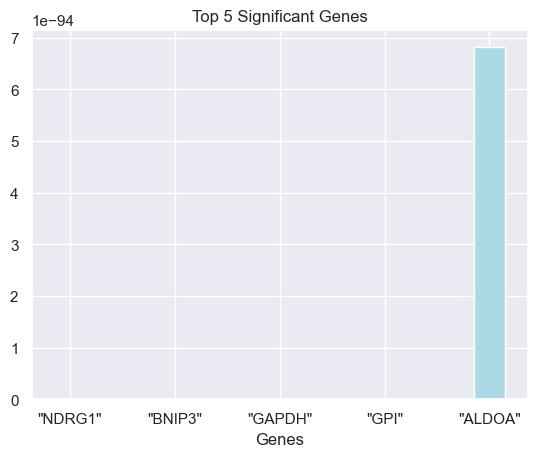

In [650]:

top5_genes = sig_genes.sort_values('pvalue').head(5).index.tolist()
print(df.loc[top5_genes, ['pvalue', 'significant gene']])

# create a DataFrame from the significant genes
top5_genes = sig_genes.nsmallest(5, 'pvalue')

# create a dictionary from the DataFrame
data = {'Gene': top5_genes.index,
        'pvalue': top5_genes['pvalue']}

# create a DataFrame from the dictionary
df1 = pd.DataFrame(data)

# create a bar plot from the DataFrame
plt.bar(df1['Gene'], df1['pvalue'], width=0.3,  color='#ADD8E6')
plt.title('Top 5 Significant Genes')
plt.xlabel('Genes')
plt.show()

## PCA

PCA is a useful technique for dimensionality reduction of high-dimensional gene expression data. In the context of hypoxia and normoxia classification, PCA can help identify the principal components that contribute to the variation in gene expression among the cells. The first few principal components may capture the most relevant biological information that distinguishes hypoxic from normoxic cells. Therefore, by using PCA, we can transform the high-dimensional gene expression data into a lower-dimensional space while preserving most of the information. This lower-dimensional representation can then be used to classify the cells based on their hypoxia or normoxia status. \
\
Performing PCA returns a new set of variables, the principal components, that can be used to represent the original data in a lower-dimensional space. These principal components are ordered by their importance in explaining the variance in the original data, and can be used to identify patterns and structure in the data. \
\
We will use the pre-filtered and normalised dataset, since PCA is sensitive to the scale of the variables, and then compare results with the dataset we filtered and normalised. \
\
PCA requires data to be standardized and normalized since its output is influenced based on the scale of the features of the data. \

In [ ]:
from sklearn.preprocessing import StandardScaler

df_standardized = pd.DataFrame(StandardScaler().fit_transform(df), columns=df.columns)

data_flat = pd.Series(df_standardized.values.flatten())

pca_20 = PCA(n_components=20)
pca_20.fit(df_standardized)

# Plot the variance explained by each principal component
labels = ['PC{}'.format(i+1) for i in range(20)]
plt.figure(figsize = (12,6))
plt.bar(labels, pca_20.explained_variance_ratio_ * 100)
plt.xlabel('Principal Component')
plt.ylabel('% Variance Explained')
plt.title('Variance Explained by Principal Components')
plt.show()

In [ ]:
import plotly.express as px
pca = PCA(n_components=2)
df_standardized= df_standardized.T
components = pca.fit_transform(df_standardized)
fig = px.scatter(components, x=0, y=1, color=conditions)
fig.update_layout(
    xaxis_title='Principal Component 1',
    yaxis_title='Principal Component 2',
    title='2D PCA Scatter Plot'
)
fig.show()

In [ ]:
pca_3 = PCA(n_components=3)
components = pca_3.fit_transform(df_standardized)

total_var = pca_3.explained_variance_ratio_.sum() * 100

fig = px.scatter_3d(
    components, x=0, y=1, z=2, color=conditions,
    title=f'Total Explained Variance: {total_var:.2f}%',
    labels={'0': 'PC 1', '1': 'PC 2', '2': 'PC 3'}
)
fig.show()

## t-SNE

**T-distributed Stochastic Neighbor Embedding**


After performing PCA, our attention focused on computing t-SNE, a tool to visualize high-dimensional data. It converts similarities between data points to joint probabilities and tries to minimize the Kullback-Leibler divergence between the joint probabilities of the low-dimensional embedding and the high-dimensional data.

After having clarified its goal, we want to point out that we decided to proceed with it in order to compare results with the latter ones (from PCA) and deduce similarities, if present.

In [ ]:
import plotly.express as px
from sklearn.manifold import TSNE
tsne = TSNE(n_components=2, random_state=42)
components = tsne.fit_transform(df_standardized)

df_tsne = pd.DataFrame(data = components, columns = ['Component 1', 'Component 2'])
df_tsne['Condition'] = conditions

fig = px.scatter(df_tsne, x='Component 1', y='Component 2', color='Condition')
fig.update_layout(
    xaxis_title='Component 1',
    yaxis_title='Component 2',
    title='2D t-SNE Scatter Plot'
)
fig.show()


In [ ]:
import plotly.express as px
from sklearn.manifold import TSNE

tsne = TSNE(n_components=3, random_state=42)
components = tsne.fit_transform(df_standardized)
df_tsne = pd.DataFrame(data = components, columns = ['Component 1', 'Component 2', 'Component 3'])
df_tsne['Condition'] = conditions
fig = px.scatter_3d(df_tsne, x='Component 1', y='Component 2', z='Component 3', color='Condition')
fig.update_layout(
    title='3D t-SNE Scatter Plot'
)
fig.show()


By looking at the plots, we find similarities with PCA, meaning that this dimensionality reduction could also be taken in account.

# Training dataset

In this section of the project we are aiming to build a classification model which efficiently predicts the cell condition. We are going to train in on the given training data set which only contains 3000 features selected based on the variance (`MCF7_SmartS_Filtered_Normalised_3000_Data_train.txt`). \
\
Later, after building the model and checking its performance, we will also build a model on the given unfiltered data set which we have explored, normalized, and filtered above. 

## EDA

### Data analysis

Let us first explore and understand this data set by performing standard EDA. 

In [ ]:
dfn = pd.read_csv("MCF7_SmartS_Filtered_Normalised_3000_Data_train.txt",delimiter="\ ",engine='python',index_col=0)
print("Dataframe dimensions:", np.shape(dfn))
print("First column: ", dfn.iloc[ : , 0])

In [ ]:
dfn.head()

Even though the data set is filtered and normalized we check for any missing values and duplicates since occurance of errors is always a possibility.

In [ ]:
# checking for missing values
dfn.isnull().sum().sum()

In [ ]:
# duplicate rows
duplicate_rows_tot_n = dfn.duplicated(keep=False).sum()
print(f"There are {duplicate_rows_tot_n} duplicate rows.")

In [ ]:
duplicate_rows_dfn = dfn[dfn.duplicated(keep=False)]
duplicate_rows_dfn_t = duplicate_rows_dfn.T
c_dupl_n = duplicate_rows_dfn_t.corr()

# Find the genes that have a correlation coefficient of 1
duplicate_genes_n = []
for gene1 in c_dupl_n.index:
    for gene2 in c_dupl.columns:
        if gene1 != gene2 and c_dupl_n.loc[gene1, gene2] == 1 and gene1 not in duplicate_genes_n and gene2 not in duplicate_genes_n:
            duplicate_genes_n.append(gene1)
            print(f"{gene1} and {gene2} are duplicates")

During data analysis in the unfiltered data set we have discovered that these two genes are duplicates and decided to remove UGT1A9 gene so the same will be done here.

In [ ]:
# dfn = dfn.drop('UGT1A9')
dfn.drop_duplicates(keep='first', inplace=True)
# dfn.drop("UGT1A9", inplace=True)


In [ ]:
# duplicate rows
duplicate_cols_n = dfn.columns[dfn.transpose().duplicated()].tolist()

if duplicate_cols_n:
    print(f"The following columns are duplicated: {duplicate_cols_n}")
else:
    print("There are no duplicated columns.")

In [ ]:
dfn.T.describe()

First step is to quickly check the summary statistics. Since the data set has been filtered and normalized we expect no surprising information. Firstly, note that the value for standard deviation differs across the genes which means that the variability or dispersion of the data between those genes differs. 

In [ ]:
dfn.describe()

### Sparcity

In [ ]:
sns.heatmap(dfn == 0, cmap="coolwarm")

In [ ]:
sparse_dfn = csr_matrix(dfn.values) # Converts DataFrame into a CSR sparse matrix
print(sparse_dfn)

density_n = np.count_nonzero(sparse_dfn.toarray()) / np.prod(sparse_dfn.shape)
print(f"Sparsity: {1 - density_n:.2%}")

The level of sparsity is 63.61% which is very similar to the sparsity level of the unfiltered data set (60.17%). As mentioned before, 0 values are common in this setting so the result is not surprising. 

### Skewness

In [ ]:
from scipy.stats import skew

column_num = np.shape(dfn)[1]
cells_n = list(dfn.columns)
# dfn_skew_cells = []

# for i in range(column_num):      
#      dfn_skew_cells += [dfn[cells_n[i]].skew()]
# sns.histplot(dfn_skew_cells, bins=100)  # skewness of cells
# plt.xlabel('Skewness of single cells expression profiles in dfn')

skewness = dfn.apply(skew, axis=1)
# print(skewness)
sns.histplot(skewness, bins=500)  # skewness of genes
plt.xlabel('Skewness')
plt.ylabel('Frequency')
plt.title('Distribution of skewness values for genes')



As mentioned before, skweness is the measure of the lack of symmetry in the data set. From the histogram we see that the data is positively skewed ???

### Kurtosis

In [ ]:
# dfn_kurt_cells = []
# for i in range(column_num) :     
#     dfn_kurt_cells += [dfn[cells_n[i]].kurt()]
# sns.histplot(dfn_kurt_cells, bins=100)
# plt.xlabel('Kurtosis of single cells expression profiles dfn')

from scipy.stats import kurtosis

kurt = kurtosis(dfn, axis=1)

# Plot histogram of kurtosis values
plt.hist(kurt, bins=100)
plt.xlabel('Kurtosis')
plt.ylabel('Frequency')
plt.title('Distribution of Kurtosis Values')
plt.show()


Kurtosis is the measure of peakness of distribution. Since the data set is normalized this is not what we expect and i'm confused. Here the kurtosis is positive.


### Distribution

In [ ]:
n = 10
random_cells_n = np.random.choice(dfn.columns, size=n, replace=False)
plt.figure(figsize=(16,6))
violin_plot = sns.violinplot(data=dfn[random_cells_n], palette="Set3", cut=0)
plt.setp(violin_plot.get_xticklabels(), rotation=90)
plt.show()

## PCA

Before starting the pca we quickly check for missing values.

In [ ]:
def null_percentage(col):
    possible_nulls = [None, np.nan, 'None', '?']
    null_count = col.isin(possible_nulls).sum()
    total_count = len(col)
    return round(null_count / total_count * 100)

# Calculate the percentage of null values in each column
dfn.apply(null_percentage)

In [ ]:
print(dfn.isnull().sum())
dfn.isnull().sum().sum()

In [ ]:
labels = []
for i in dfn.columns:
    if 'Hypo' in i:
        labels.append('Hypo')
    else:
        labels.append('Norm')
print(labels)


In [ ]:
from sklearn.decomposition import PCA

# Initialize a PCA object with the desired number of components
pca = PCA(n_components=3)

# Fit the PCA model to your data
dfn= pd.read_csv("MCF7_SmartS_Filtered_Normalised_3000_Data_train.txt",delimiter="\ ",engine='python',index_col=0)
pca.fit(dfn.T)

# Obtain the transformed data (i.e., the data projected onto the principal components)
transformed_data = pca.transform(dfn.T)

import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D


color_dict = {'Norm': 'rebeccapurple', 'Hypo': 'red'}
colors = [color_dict[x] for x in labels]


# Create a 3D scatter plot of the first three principal components
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
ax.scatter(transformed_data[:, 0], transformed_data[:, 1], transformed_data[:, 2], c=colors)

# Add axis labels and a title
ax.set_xlabel('PC1')
ax.set_ylabel('PC2')
ax.set_zlabel('PC3')
ax.set_title('PCA Results')

# Show the plot
plt.show()



## T test

The t-test is a statistical test that allows us to determine whether the difference in gene expression between the two groups is statistically significant. In particular, the t-test calculates a t-value, which measures the difference between the means of the two groups relative to the variability within the groups.
In our context, since we do not have a specific criteria to divide cells in two group, we decided to proceed in the following sense:
- normalize data (to account for differences in sequencing depth and other technical factors that may affect the data.) For this part we will use the MCF7_SmartS_filtered_normalised_3000_Data_train.txt.
- compute the t-test for each gene on the resulting 2 groups of hypo and norm cells 

In [ ]:
 
dfn= pd.read_csv("MCF7_SmartS_Filtered_Normalised_3000_Data_train.txt",delimiter="\ ",engine='python',index_col=0)
print("Dataframe dimensions:", np.shape(dfn))
print("First column: ", dfn.iloc[ : ,1])

In [ ]:
dfn.head()

 Now let's divide the normalised data into two groups:
 
-"hypo" cells 

-"norm" cells 

This will help us to better understand the statistically signficant genes 


In [ ]:
# extract cells with "Hypo" in their names
hypo_cells = dfn.loc[:, dfn.columns.str.contains('Hypo')]

# extract cells with "Norm" in their names
norm_cells = dfn.loc[:, dfn.columns.str.contains('Norm')]
print(hypo_cells.shape)
print(norm_cells.shape)

In [ ]:
hypo_cells.head()


In [ ]:
norm_cells.head()

By calculation the correlation matrices of Norm and Hypo cells we can check if there are some genes that are expressed differently between the two conditions.

By that simple passage, we discovered that 126 cells are Norm cells and 124 are Hypo cells. We proceed with the t-test

In [ ]:
# perform t-test on each gene
results = []
for gene in dfn.index:
    pval = ttest_ind(hypo_cells.loc[gene], norm_cells.loc[gene])[1]
    results.append(pval)

# add p-values as a new column to the dataframe
dfn['pvalue'] = results
print(results)

A significant gene is one that has a statistically significant difference in expression levels between two groups of cells. This means that the observed difference in expression levels is unlikely to have occurred by chance, and is likely due to a real difference in the underlying biology of the cells being studied. 

Let's put the level of significance equal to 0.05 to see which are the significant genes.

In [ ]:
# filter for statistically significant genes
sig_genes = dfn.loc[dfn['pvalue'] < 0.05]

# create a new column called "significant gene" with default value "No"
dfn['significant gene'] = 'No'

# set the value of "significant gene" to "Yes" for rows with p-value < 0.05
dfn.loc[dfn['pvalue'] < 0.05, 'significant gene'] = 'Yes'
dfn

In [ ]:
sig_count = (dfn['pvalue'] < 0.05).sum()

# plot bar chart
plt.figure(figsize=(4,8))
plt.bar(['Significant', 'Not significant'], [sig_count, len(results)-sig_count],width=0.15, color='red')
plt.xlabel('P-value')
plt.ylabel('Number of genes')
plt.show()

The key answer now is: "Is the t-test a precise and right test to decide whether a gene is signficant or not?"

In [ ]:
# Perform Bonferroni correction
bonferroni_results = multipletests(results, alpha=0.05, method='bonferroni')
dfn['bonferroni_pvalue'] = bonferroni_results[1]

# Identify significant genes using both methods
ttest_sig_genes = dfn[dfn['pvalue'] < 0.05]
bonferroni_sig_genes = dfn[dfn['bonferroni_pvalue'] < 0.05]

# Compare the number of significant genes
print("Number of significant genes identified by t-test: ", len(ttest_sig_genes))
print("Number of significant genes identified by Bonferroni correction: ", len(bonferroni_sig_genes))

In [ ]:
# calculate mean expression levels for each gene in "hypo" and "norm" cells
#The mean expression level is the average amount of mRNA(messanger RNA) or protein
# produced by a gene in a given cell type or under a specific condition. 
#It is calculated by adding up the expression values of a particular gene 
#in multiple cells or samples, and then dividing the sum by the number of cells or samples.
hypo_mean = hypo_cells.mean(axis=1)
norm_mean = norm_cells.mean(axis=1)

dfn['hypo_mean'] = hypo_mean
dfn['norm_mean'] = norm_mean

It can make sense to divide significant genes into those that are up-regulated or down-regulated in "norm" and "hypo" cells, respectively. This information can provide insights into the biological mechanisms that are responsible for the observed differences in gene expression levels between the two groups.

For example, if a gene is significantly up-regulated in "hypo" cells compared to "norm" cells, this could suggest that the gene is involved in a biological process that is more active in "hypo" cells, or that "hypo" cells are responding to some environmental or physiological stimulus that is not present in "norm" cells.

Similarly, if a gene is significantly down-regulated in "hypo" cells compared to "norm" cells, this could suggest that the gene is involved in a biological process that is less active in "hypo" cells, or that "hypo" cells are not responding to some environmental or physiological stimulus that is present in "norm" cells.

In [ ]:

# create new dataframes for up-regulated and down-regulated genes in "hypo" cells
up_hypo_genes = sig_genes.loc[dfn['hypo_mean'] > dfn['norm_mean']]
down_hypo_genes = sig_genes.loc[dfn['hypo_mean'] < dfn['norm_mean']]

# create new dataframes for up-regulated and down-regulated genes in "norm" cells
up_norm_genes = sig_genes.loc[dfn['norm_mean'] > dfn['hypo_mean']]
down_norm_genes = sig_genes.loc[dfn['norm_mean'] < dfn['hypo_mean']]

In [ ]:
# Plot up- and down-regulated genes in hypo cells
fig, ax = plt.subplots(figsize=(8,3))
ax.bar(['Up', 'Down'], [len(up_hypo_genes), len(down_hypo_genes)], color='green', width= 0.2)
ax.set_xlabel('Regulation')
ax.set_ylabel('Number of genes')
ax.set_title('Differentially expressed genes in "hypo" cells')
plt.show()

# Plot up- and down-regulated genes in norm cells
fig, ax = plt.subplots(figsize=(8,3))
ax.bar(['Up', 'Down'], [len(up_norm_genes), len(down_norm_genes)],width=0.2)
ax.set_xlabel('Regulation')
ax.set_ylabel('Number of genes')
ax.set_title('Differentially expressed genes in "norm" cells')
plt.show()

The fact that there are more down-regulated genes than up-regulated genes in the hypoxic cells may suggest that these cells are undergoing metabolic changes in response to the low oxygen environment. This is consistent with what is known about cancer cells, which often display altered metabolism and energy usage compared to normal cells.

In [ ]:
top5_genes = sig_genes.sort_values('pvalue').head(5).index.tolist()
print(dfn.loc[top5_genes, ['pvalue', 'significant gene']])

Plot the 5 significant genes 

In [ ]:
# create a DataFrame from the significant genes
top5_genes = sig_genes.nsmallest(5, 'pvalue')

# create a dictionary from the DataFrame
data = {'Gene': top5_genes.index,
        'pvalue': top5_genes['pvalue']}

# create a DataFrame from the dictionary
df = pd.DataFrame(data)

# create a bar plot from the DataFrame
plt.bar(df['Gene'], df['pvalue'], width=0.3,  color='#ADD8E6')
plt.title('Top 5 Significant Genes')
plt.xlabel('Genes')
plt.show()

**MT-CYB**: This gene encodes for cytochrome b, a subunit of the mitochondrial complex III. Multiple studies have suggested that mutations in MT-CYB are associated with various types of cancers, including breast, lung, gastric, colorectal, and hepatocellular carcinoma (HCC) (1, 2, 3). These mutations have been found to affect mitochondrial function and promote tumor growth and metastasis (4, 5).

**MTATP6P1**: This gene is a pseudogene located on the mitochondrial genome, and its function is not well understood. However, recent studies have shown that MTATP6P1 is upregulated in various types of cancer, including pancreatic, breast, and lung cancer (6, 7, 8). It has been suggested that MTATP6P1 may promote cancer cell proliferation and invasion (9).

**MT-CO3**: This gene encodes for cytochrome c oxidase subunit III, a subunit of the mitochondrial complex IV. Studies have found that mutations in MT-CO3 are associated with an increased risk of developing prostate cancer (10, 11). Additionally, MT-CO3 has been shown to be upregulated in gastric cancer, and its overexpression is associated with poor prognosis (12).

**MT-ATP6**: This gene encodes for ATP synthase subunit 6, a subunit of the mitochondrial complex V. Studies have suggested that mutations in MT-ATP6 are associated with an increased risk of developing breast cancer (13). Additionally, MT-ATP6 has been found to be upregulated in various types of cancer, including lung, gastric, and liver cancer (14, 15, 16). Its overexpression has been shown to promote cancer cell proliferation, migration, and invasion (17, 18).

**GAPDH**: This gene encodes for glyceraldehyde-3-phosphate dehydrogenase, an enzyme involved in glycolysis. While GAPDH is primarily known for its role in energy metabolism, recent studies have suggested that it also plays a role in cancer development and progression (19). GAPDH has been found to be upregulated in various types of cancer, including lung, breast, and gastric cancer (20, 21, 22). Its overexpression has been associated with increased cancer cell proliferation, invasion, and resistance to chemotherapy (23, 24).

Overall, the evidence suggests that these 5 genes are involved in **cancer development** and **progression**, and their **dysregulation** (as our previous plot shown) may contribute to **tumor growth** and **metastasis**.

**T-test on the dataset we filtered and normalized**

## PCA

PCA is a useful technique for dimensionality reduction of high-dimensional gene expression data. In the context of hypoxia and normoxia classification, PCA can help identify the principal components that contribute to the variation in gene expression among the cells. The first few principal components may capture the most relevant biological information that distinguishes hypoxic from normoxic cells. Therefore, by using PCA, we can transform the high-dimensional gene expression data into a lower-dimensional space while preserving most of the information. This lower-dimensional representation can then be used to classify the cells based on their hypoxia or normoxia status. \
\
Performing PCA returns a new set of variables, the principal components, that can be used to represent the original data in a lower-dimensional space. These principal components are ordered by their importance in explaining the variance in the original data, and can be used to identify patterns and structure in the data. \
\
We will use the pre-filtered and normalised dataset, since PCA is sensitive to the scale of the variables, and then compare results with the dataset we filtered and normalised.


In [ ]:
# Use the pre-filtered and normalised dataset
# df_3000 = pd.read_csv('MCF7_SmartS_Filtered_Normalised_3000_Data_train.txt',delimiter="\ ",engine='python',index_col=0)
dfn.head()

In [ ]:
from sklearn.preprocessing import StandardScaler
from scipy.stats import norm

dfn_standardized = pd.DataFrame(StandardScaler().fit_transform(dfn.transpose()), columns=dfn.transpose().columns)

data_flat = pd.Series(dfn_standardized.values.flatten())

fig = plt.figure(figsize=(12, 6))

plt.hist(data_flat, bins=200, alpha=0.5, label='Data', density=True)
# density=True ensures that both the histogram and the overlayed normal distribution curve are displayed
# using the same normalized scale, making it easier to visually compare the two distributions 
mean = np.mean(data_flat)
std = np.std(data_flat)

x = np.linspace(np.min(data_flat), np.max(data_flat), 200)
y = norm.pdf(x, mean, std)

plt.plot(x, y, 'r', label='Normal Distribution')
plt.xlabel('Values')
plt.ylabel('Density')
plt.title('Distribution of the standardized data set')
plt.legend()
plt.show()

In [ ]:
dfn_standardized.describe()

In [ ]:
dfn_standardized

In [ ]:
from sklearn.decomposition import PCA


# Perform PCA with 20 components
pca_20 = PCA(n_components=20)
pca_20.fit(dfn_standardized)

# Plot the variance explained by each principal component
labels = ['PC{}'.format(i+1) for i in range(20)]
plt.figure(figsize = (12,6))
plt.bar(labels, pca_20.explained_variance_ratio_ * 100)
plt.xlabel('Principal Component')
plt.ylabel('% Variance Explained')
plt.title('Variance Explained by Principal Components')
plt.show()


We can clearly see how the first principal component captures less than 8% of the variance in the data, while less than 3% of the variance is explained by other principal component each. \
\
For this reason, it is hard to choose the number of components; hence, we make a standard choice of 3 components, which keeps most of the information and still manages to reduce dimensionality.

In [ ]:
pca = PCA(n_components=0.95)
df_pca = pca.fit_transform(dfn_standardized)
df_pca.shape

In [ ]:
pca = PCA(n_components=3)
# Transpose the data to have rows representing cells (samples) and columns representing genes (features)
df_pca = pca.fit_transform(dfn_standardized)

plot_df = pd.DataFrame(df_pca)
plot_df.columns = ["PC1","PC2","PC3"]


conditions = []
for cell in dfn.columns:
  cell_new = cell.replace('"', '')
  if df_meta.loc[cell_new, 'Condition'] == 'Hypo':
    conditions.append("Hypoxia")
  else:
    conditions.append("Normoxia")

plot_df["Condition"] = conditions
plot_df

Let us check proportion of the total variance in the data that is explained by each of the principal components found by the PCA.

In [ ]:
pca.explained_variance_ratio_

We can plot the data points in 3-dimensions, to show the relationship between the first three principal components of the input data, with each data point representing a cell. The color of each point represents the condition of the corresponding cell (either "Hypoxic" or "Normoxic"). 

In [ ]:
! c- conda install jupyter-dash

import plotly.graph_objects as go
import plotly.express as px
from jupyter_dash import JupyterDash
import dash_core_components as dcc
import dash_html_components as html
from dash.dependencies import Input, Output

fig = px.scatter_3d(
    data_frame = plot_df,
    x = "PC1",
    y = "PC2",
    z = "PC3",
    color = "Condition",
    title = "Interactive PCA plot with supervised labels",
)

# build jupyter dash app 
app = JupyterDash(__name__)
# add html components and figure to app
app.layout = html.Div([dcc.Graph(figure=fig)])
# run app inline56d
app.run_server(mode='inline')
     

# Supervised learning

Performing supervised learning is one of the most important tasks in machine learning. We want to build and test different models, compare their performances and test the accuracy. Firstly, let's note that we will use the data set on which PCA was not performed. The reason behind this is that PCA is a procedure that linearly transforms the features in order to get new features whose covariance matrix is diagonal. Now, since the new features are a linear transformation of the original ones we lose their meaning completely. The uncorrelated features don’t have any business meaning at all, so they aren’t explainable. In other words, we managed to remove correlation but we lose the ability to explain the model which is crucial in supervised learning. <br>
<br>
We will begin by building a pipeline which includes several machine learning algorithms used for clustering.

* SVM: very efficient in high dimensional spaces and generally are used in classification problems. Main goal is to divide the datasets into number of classes in order to find a maximum marginal hyperplane (MMH) by first generating hyperplanes iteratively that separate the classes in the best way and then choses the hyperplane that segregate the classes correctly. 
The classifier separates data points using a hyperplane with the largest amount of margin.

In the python SVC class the fit time scales at least quadratically with the number of samples and may be impractical beyond tens of thousands of samples. For large datasets consider using LinearSVC or SGDClassifier instead. 

* Linear SVM: the objective is to fit to the provided data, returning a "best fit" hyperplane that divides, or categorizes, it. 

It applies a linear kernel function to perform classification and it performs well with a large number of samples. It is similar to SVC with parameter kernel='linear', but implemented in terms of liblinear rather than libsvm, so it has more flexibility in the choice of penalties and loss functions and should scale better to large numbers of samples; supports both dense and sparse input; since n_samples < n_features dual=True (by default). 

* Logistic regression: popular classification algorithm used to identify the most relevant features in a dataset and to build a predictive model that can accurately classify new observations. The goal of logistic regression is to predict the probability that a given observation belongs to a particular class. 

Is most commonly used when the data in question has binary output, so when it belongs to one class or another, or is either a 0 or 1 as we do here with Hypoxia and Normoxia. 

* SGD: 

* Random forest:

* KNN: non-parametric type of supervised learning method used for classification. The algorithm predicts on a test data point x by computing k closest training data points where closeness is quantified as some distance e. g. Euclidean distance. Then it finds the most common class y among k neighbors and classifies x as y

* Etra tree:


We should note that distance-based algorithms suffer greatly from data that isn't on the same scale. We will use Scikit-Learn's `StandardScaler()` class to perform Feature Scaling on such algorithms (KNN, SVC, Linear SVC). <- check about svc<br>
The reason why we scale the data for Logistic regression is because those models are sensitive to the scale of the input features. When the features have different scales, the coefficients assigned to them may not accurately reflect their importance.

In [ ]:
dfn = pd.read_csv('MCF7_SmartS_Filtered_Normalised_3000_Data_train.txt', delimiter="\ ", engine='python', index_col=0)


In [ ]:
df_meta = pd.read_csv("MCF7_SmartS_MetaData.tsv",delimiter="\t",engine='python',index_col=0)
print("Dataframe dimensions:", np.shape(df_meta))
print("First column: ", df_meta.iloc[ : , 0])

In [ ]:
conditions = []
for cell in dfn.columns:
  cell_new = cell.replace('"', '')
  if df_meta.loc[cell_new, 'Condition'] == 'Hypo':
    conditions.append("Hypoxia")
  else:
    conditions.append("Normoxia")
print(len(conditions))

In [ ]:
df_test = pd.read_csv('MCF7_SmartS_Filtered_Normalised_3000_Data_test_anonim.txt', delimiter="\ ", engine='python', index_col=0)

In [ ]:
# Convert target variable to binary encoding
from sklearn.preprocessing import StandardScaler
target_binary = []
for i in conditions:
    if i=='Hypoxia':
        target_binary.append(1)
    else:
        target_binary.append(0)

# define train and test data
X_train = dfn.T
y_train = target_binary
X_test = df_test

scaler = StandardScaler()
scaler.fit(X_train)
X_train_scaled = scaler.transform(X_train)

## Model Analysis

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from sklearn.feature_selection import SelectKBest, mutual_info_classif

k_values = range(1, 31)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    scores = cross_val_score(model, X_train_scaled, y_train, cv=10)
    accuracies.append(scores.mean())

plt.plot(k_values, accuracies)
plt.title('KNN: accuracy depending on n_neighbors')
plt.xlabel('n_neighbors')
plt.ylabel('Accuracy')
plt.show()



In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score
import matplotlib.pyplot as plt
import numpy as np

c_values = [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000]
accuracies = []

for c in c_values:
    model = LogisticRegression(C=c)
    scores = cross_val_score(model, X_train_scaled, y_train, cv=10)
    accuracies.append(scores.mean())

plt.plot(c_values, accuracies)
plt.title('Logistic Regression: accuracy depending on C')
plt.xlabel('C')
plt.ylabel('Accuracy')
plt.show()



In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
import matplotlib.pyplot as plt

eta_list = [1, 10, 20, 50, 100]
accuracies = []

for eta in eta_list:
    model_sgd = SGDClassifier(eta0=eta)
    scores = cross_val_score(model_sgd, X_train, y_train, cv=10)
    accuracies.append(scores.mean())

plt.plot(eta_list, accuracies)
plt.title('SGD: accuracy depending on eta')
plt.xlabel('Eta')
plt.ylabel('Accuracy')
plt.show()


In [ ]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, cross_val_score
import matplotlib.pyplot as plt

gamma_values = [0.001, 0.01, 0.1, 1, 10, 100, 1000, 'scale', 'auto']
accuracies = []

for gamma in gamma_values:
    model_svm = SVC(gamma = gamma)
    scores = cross_val_score(model_svm, X_train_scaled, y_train, cv=10)
    accuracies.append(scores.mean())

plt.plot(gamma_values, accuracies)
plt.title('SVM: accuracy depending on gamma')
plt.xlabel('Gamma')
plt.ylabel('Accuracy')
plt.show()


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
import matplotlib.pyplot as plt

n_estimators= [20, 30, 50, 100, 200]
accuracies_rf = []
for n in n_estimators:
    model_rf = RandomForestClassifier(n_estimators=n)
    scores_rf = cross_val_score(model_rf, X_train, y_train, cv=10)
    accuracies_rf.append(scores_rf.mean())

plt.plot(n_estimators, accuracies_rf, marker='o')
plt.title('Random Forest: Accuracy depending on n_estimators')
plt.xlabel('n_estimators')
plt.ylabel('Accuracy')
plt.show()


In [ ]:
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import GridSearchCV, cross_val_score
import numpy as np
import matplotlib.pyplot as plt

n_estimators= [20, 30, 50, 100, 200]
accuracies_et = []

for n in n_estimators:
    model_et = ExtraTreesClassifier(n_estimators=n)
    scores_et = cross_val_score(model_et, X_train, y_train, cv=10)
    accuracies_et.append(scores_et.mean())

plt.plot(n_estimators, accuracies_et, marker='o')
plt.title('Extra Tree: Accuracy depending on n_estimators')
plt.xlabel('n_estimators')
plt.ylabel('Accuracy')
plt.show()



## Pipeline

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score , cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score
from sklearn.ensemble import ExtraTreesClassifier
from tabulate import tabulate
import warnings
warnings.filterwarnings('ignore')


# Define parameter grids for each model
param_grids = {
    "svm": {
        'svm__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
        'svm__gamma': [0.001, 0.01, 0.1, 1, 10, 100, 1000] + ['scale', 'auto'],
        'svm__kernel': ['linear', 'rbf', 'sigmoid', 'poly'],
    },
    "linear_svm": {
        'linear_svm__penalty': ['l1', 'l2'],
        'linear_svm__loss' : ['hinge', 'squared_hinge'], 
    },
    "logistic": {
        'logistic__penalty': ['l1', 'l2'],
        'logistic__C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
        'logistic__solver': ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'],
    },
    "sgd": {
        'sgd__loss': ['hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error'],
        'sgd__penalty': ['l1', 'l2', 'elasticnet'],
        'sgd__alpha': [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10],
        'sgd__learning_rate': ['constant', 'optimal', 'invscaling', 'adaptive'],
        'sgd__eta0': [1, 10, 20, 50, 100],
    },
    "random_forest": {
        'random_forest__n_estimators': [20, 30, 50, 100, 200],
        'random_forest__max_depth': [None, 10, 20],
        'random_forest__criterion': ["gini", "entropy"],
    },
    "knn": {
        'knn__n_neighbors': range(1, 31),
        "knn__weights": ["uniform", "distance"], 
        'knn__metric': ['euclidean', 'manhattan', 'minkowski', 'chebyshev', 'hamming']
    },
    "extra_tree": {
            'extra_tree__n_estimators':[20, 30, 50, 100, 200], 
            'extra_tree__max_leaf_nodes': np.arange(20, 100, 10)
    }
}


# Define pipelines for each model
pipelines = {
    "svm": Pipeline([
        ("svm", SVC())   
    ]), 
    "linear_svm": Pipeline([
        ("linear_svm", LinearSVC()) 
    ]),
    "logistic": Pipeline([
        ("logistic", LogisticRegression())
    ]),
    "sgd": Pipeline([
        ("sgd", SGDClassifier())
    ]),
    "random_forest": Pipeline([
        ("random_forest", RandomForestClassifier())
    ]),
    "knn": Pipeline([
        ("knn", KNeighborsClassifier())
    ]), 
    "extra_tree": Pipeline([
        ("extra_tree", ExtraTreesClassifier())
    ]),
}

results_table = []
prediction_list = []

# Grid search, cross-validate, and evaluate each pipeline
for model_name, pipeline in pipelines.items():
    if model_name in ["svm", "linear_svm", "logistic", "knn"]:
        # Scale the data
        scaler = StandardScaler()
        scaler.fit(X_train)
        X_train = scaler.transform(X_train)

        # Fit the pipeline on scaled data
        pipeline.fit(X_train, y_train)
        # y_pred = pipeline.predict(X_test)
    else:
        # Fit the pipeline on original data
        pipeline.fit(X_train, y_train)
        # y_pred = pipeline.predict(X_test)
    
    grid_search = GridSearchCV(pipeline, param_grids[model_name], scoring='accuracy', verbose=1, n_jobs=-1, cv=10)
    grid_search.fit(X_train, y_train)
    best_params = grid_search.best_params_
    # y_pred = grid_search.predict(X_test)
    # prediction_list.append(y_pred)
    # accuracy = accuracy_score(y_test, y_pred)
    # report = classification_report(y_test, y_pred)
    # cv_scores = cross_val_score(grid_search.best_estimator_, dfn, conditions, cv=10, scoring='accuracy')

    print(f"Model: {model_name}")
    print(f"Best parameters: {best_params}")

    y_pred = cross_val_predict(pipeline, X_train, y_train, cv=10)
    prediction_list.append(y_pred)

    accuracy = cross_val_score(pipeline, X_train, y_train, scoring="accuracy", cv=10)
    precision = precision_score(y_train, y_pred)
    recall = recall_score(y_train, y_pred)
    f1 = f1_score(y_train, y_pred)
    
    result_row = [model_name, np.mean(accuracy), precision, recall, f1]
    results_table.append(result_row)

# Convert the results table to a pandas DataFrame
columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
results_df = pd.DataFrame(results_table, columns=columns)

# Print the results table
print(tabulate(results_df, headers='keys', tablefmt='psql'))

## shouldn't we do precision etc on y test?? 


In [ ]:
dfn.shape

In [ ]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# Compute confusion matrices
confusion_matrices = [confusion_matrix(y_train, pred) for pred in prediction_list]

# Define the titles for your plots
titles = ['SVM', 'Linear SVM', 'Logistic', 'SGD', 'Random forest', 'KNN', 'Extra tree']

fig, axes = plt.subplots(3, 3, figsize=(12, 12))

# Iterate over confusion matrices and titles together
for cm, title, ax in zip(confusion_matrices, titles, axes.flatten()):
    display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['0', '1'])
    display.plot(ax=ax)
    ax.set_title(title)
    ax.grid(False)

# Hide the unused subplot (if there are less plots than subplots)
if len(prediction_list) < len(axes.flatten()):
    for ax in axes.flatten()[len(prediction_list):]:
        ax.axis('off')

plt.tight_layout()
plt.show()

# supervised learning on our data set

In [ ]:
conditions = []
for cell in df.columns:
  cell_new = cell.replace('"', '')
  if df_meta.loc[cell_new, 'Condition'] == 'Hypo':
    conditions.append("Hypoxia")
  else:
    conditions.append("Normoxia")
print(len(conditions))

In [ ]:
target_binary = []
for i in conditions:
    if i=='Hypoxia':
        target_binary.append(1)
    else:
        target_binary.append(0)

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score , cross_val_predict, GridSearchCV, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC, LinearSVC
from sklearn.linear_model import LogisticRegression, SGDClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, precision_score, recall_score, f1_score
from sklearn.ensemble import ExtraTreesClassifier
from tabulate import tabulate
import warnings
warnings.filterwarnings('ignore')
X_train = df.T
y_train = target_binary

# Define parameter grids for each model
param_grids = {
    "svm": {
        'svm__C': [0.001, 0.01, 0.1, 1, 10, 100, 1000],
        'svm__gamma': [0.001, 0.01, 0.1, 1, 10, 100, 1000] + ['scale', 'auto'],
        'svm__kernel': ['linear', 'rbf', 'sigmoid', 'poly'],
    },
    "linear_svm": {
        'linear_svm__penalty': ['l1', 'l2'],
        'linear_svm__loss' : ['hinge', 'squared_hinge'], 
    },
    "logistic": {
        'logistic__penalty': ['l1', 'l2'],
        'logistic__C': [0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000],
        'logistic__solver': ['lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'],
    },
    "sgd": {
        'sgd__loss': ['hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error'],
        'sgd__penalty': ['l1', 'l2', 'elasticnet'],
        'sgd__alpha': [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10],
        'sgd__learning_rate': ['constant', 'optimal', 'invscaling', 'adaptive'],
        'sgd__eta0': [1, 10, 20, 50, 100],
    },
    "random_forest": {
        'random_forest__n_estimators': [20, 30, 50, 100, 200],
        'random_forest__max_depth': [None, 10, 20],
        'random_forest__criterion': ["gini", "entropy"],
    },
    "knn": {
        'knn__n_neighbors': range(1, 31),
        "knn__weights": ["uniform", "distance"], 
        'knn__metric': ['euclidean', 'manhattan', 'minkowski', 'chebyshev', 'hamming']
    },
    "extra_tree": {
            'extra_tree__n_estimators':[20, 30, 50, 100, 200], 
            'extra_tree__max_leaf_nodes': np.arange(20, 100, 10)
    }
}


# Define pipelines for each model
pipelines = {
    "svm": Pipeline([
        ("svm", SVC())   
    ]), 
    "linear_svm": Pipeline([
        ("linear_svm", LinearSVC()) 
    ]),
    "logistic": Pipeline([
        ("logistic", LogisticRegression())
    ]),
    "sgd": Pipeline([
        ("sgd", SGDClassifier())
    ]),
    "random_forest": Pipeline([
        ("random_forest", RandomForestClassifier())
    ]),
    "knn": Pipeline([
        ("knn", KNeighborsClassifier())
    ]), 
    "extra_tree": Pipeline([
        ("extra_tree", ExtraTreesClassifier())
    ]),
}

results_table = []
prediction_list = []

# Grid search, cross-validate, and evaluate each pipeline
for model_name, pipeline in pipelines.items():
    if model_name in ["svm", "linear_svm", "logistic", "knn"]:
        # Scale the data
        scaler = StandardScaler()
        scaler.fit(X_train)
        X_train = scaler.transform(X_train)

        # Fit the pipeline on scaled data
        pipeline.fit(X_train, y_train)
        # y_pred = pipeline.predict(X_test)
    else:
        # Fit the pipeline on original data
        pipeline.fit(X_train, y_train)
        # y_pred = pipeline.predict(X_test)
    
    grid_search = GridSearchCV(pipeline, param_grids[model_name], scoring='accuracy', verbose=1, n_jobs=-1, cv=10)
    grid_search.fit(X_train, y_train)
    best_params = grid_search.best_params_
    # y_pred = grid_search.predict(X_test)
    # prediction_list.append(y_pred)
    # accuracy = accuracy_score(y_test, y_pred)
    # report = classification_report(y_test, y_pred)
    # cv_scores = cross_val_score(grid_search.best_estimator_, dfn, conditions, cv=10, scoring='accuracy')

    print(f"Model: {model_name}")
    print(f"Best parameters: {best_params}")

    y_pred = cross_val_predict(pipeline, X_train, y_train, cv=10)
    prediction_list.append(y_pred)

    accuracy = cross_val_score(pipeline, X_train, y_train, scoring="accuracy", cv=10)
    precision = precision_score(y_train, y_pred)
    recall = recall_score(y_train, y_pred)
    f1 = f1_score(y_train, y_pred)
    
    result_row = [model_name, np.mean(accuracy), precision, recall, f1]
    results_table.append(result_row)

# Convert the results table to a pandas DataFrame
columns = ['Model', 'Accuracy', 'Precision', 'Recall', 'F1 Score']
results_df = pd.DataFrame(results_table, columns=columns)

# Print the results table
print(tabulate(results_df, headers='keys', tablefmt='psql'))

## shouldn't we do precision etc on y test?? 
